# Riesgo de evento adverso en el primer año después de un trasplante de médula ósea

Proyecto final de la materia de Aprendizaje Automatico. Especialización en Inteligencia Artificial, Universidad Pedagógica y Tecnológica de Colombia.

Estudiante: Oscar David Perilla Dominguez

Codigo: 202624578


Objetivo: estimar, con la información disponible antes del trasplante, la probabilidad de que un paciente tenga un evento adverso en los primeros 12 meses, y explicar de qué depende esa estimación.

## Índice

1. Problema y contexto
2. Datos y diccionario de variables
3. Calidad y limpieza de los datos
    - 3.1 Valores nulos por variable
    - 3.2 Limpieza: de df_raw a df_clean
4. Variable objetivo y partición de los datos
5. Análisis exploratorio
    - 5.1 Edad del paciente y del donante
    - 5.2 Variables clínicas principales
    - 5.3 Compatibilidad HLA y PCA
    - 5.4 Quién tiene datos vacíos
    - 5.5 Datos vacíos y seguimiento en el tiempo
    - 5.6 Conclusiones del análisis exploratorio
6. Preparación de datos: Pipeline, imputación y reducción de dimensión
7. Balanceo de clases: prueba con SMOTE
8. Comparación de modelos
9. Ajuste de hiperparámetros con GridSearchCV
10. Evaluación final en df_test
    - 10.1 Matriz de confusión y curvas
    - 10.2 Riesgo por deciles
    - 10.3 Desempeño por subgrupo
    - 10.4 Errores del modelo
11. Análisis a 6, 12 y 18 meses
12. Explicabilidad
    - 12.1 Cómo leer las contribuciones: log-odds y probabilidad
    - 12.2 Importancia por permutación
    - 12.3 SHAP: efecto de cada variable
    - 12.4 Explicación de pacientes individuales
13. Exportación del modelo y registro en MLflow
14. Conclusiones, condiciones de validez y próximos pasos

# 0. Entorno y reproducibilidad

El notebook fue ejecutado en local, dentro del entorno virtual del proyecto que crea uv, y desde la raíz del proyecto:


Para temas de replicabilidad, debera ejecutar los siguientes comandos
```
uv sync
uv run python -m jupyterlab
```

Para ejecutarlo completo y guardar todas las salidas en el mismo archivo:

```
uv run python -m nbconvert --to notebook --execute --inplace Proyecto_Final_ML_Riesgo_Post_Trasplante_Enviar.ipynb
```

Dónde queda cada resultado:

- MLflow registra dentro del proyecto, en la carpeta mlruns/, los experimentos, la comparación de modelos, cada combinación de la búsqueda de hiperparámetros, las métricas, las gráficas y los modelos. Para verlos: `uv run python -m mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` y abrir http://127.0.0.1:5000.
- Las figuras se guardan en imagenes/ (las usa el reporte) y los artefactos del modelo en despliegue/artefactos/ (los usa la aplicación).

In [ ]:
import json
import logging
import os
import platform
import random
import time
import warnings
from datetime import datetime
from pathlib import Path

os.environ["PYTHONHASHSEED"] = "42"
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
os.environ["DO_NOT_TRACK"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost
import shap
import imblearn
import mlflow
import mlflow.data
from mlflow.tracking import MlflowClient
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score, log_loss,
                             classification_report, confusion_matrix, roc_curve, precision_recall_curve,
                             recall_score, precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImblearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
AZUL, ROJO, GRIS, VERDE, OCRE = "#2F5D8A", "#B5443B", "#8C8C8C", "#3E7C5A", "#C08A2B"
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "joblib": joblib.__version__, "xgboost": xgboost.__version__,
             "imbalanced-learn": imblearn.__version__, "mlflow": mlflow.__version__,
             "shap": shap.__version__}
print(" | ".join(f"{k} {v}" for k, v in VERSIONES.items()))

python 3.12.10 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | joblib 1.6.0 | xgboost 3.4.1 | imbalanced-learn 0.14.2 | mlflow 3.18.0 | shap 0.54.1


In [2]:
%matplotlib inline

In [ ]:
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
HILOS_POR_MODELO = 4

RAIZ = Path.cwd()
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "imagenes"
CARPETA_ARTEFACTOS = RAIZ / "despliegue" / "artefactos"
CARPETA_MLRUNS = RAIZ / "mlruns"
assert (CARPETA_DATOS / "train.csv").exists(), "Ejecuta el notebook desde la raíz del proyecto, donde está la carpeta data/"
for carpeta in (CARPETA_IMAGENES, CARPETA_ARTEFACTOS, CARPETA_MLRUNS):
    carpeta.mkdir(parents=True, exist_ok=True)

logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri(f"sqlite:///{(CARPETA_MLRUNS / 'mlflow.db').as_posix()}")
EXPERIMENTO = "riesgo_post_trasplante"
if mlflow.get_experiment_by_name(EXPERIMENTO) is None:
    mlflow.create_experiment(EXPERIMENTO, artifact_location=(CARPETA_MLRUNS / "artifacts").as_uri())
mlflow.set_experiment(EXPERIMENTO)
cliente_mlflow = MlflowClient()
ID_EJECUCION = datetime.now().strftime("%Y%m%d-%H%M%S")


def iniciar_run(nombre, **kwargs):
    """Abre un run de MLflow marcado con el identificador de esta ejecución del notebook."""
    return mlflow.start_run(run_name=nombre, tags={"ejecucion": ID_EJECUCION}, **kwargs)


def registrar_variante(nombre, parametros, metricas):
    """Registra una variante de un experimento como run anidado dentro del run abierto."""
    with iniciar_run(nombre, nested=True):
        mlflow.log_params(parametros)
        mlflow.log_metrics(metricas)


def registrar_metricas(run_id, metricas):
    """Agrega métricas a un run ya creado."""
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})


def registrar_tabla(run_id, tabla, nombre):
    """Guarda una tabla como CSV dentro de un run."""
    cliente_mlflow.log_text(run_id, tabla.to_csv(), f"tablas/{nombre}.csv")


def guardar_figura(nombre, run_id=None):
    """Guarda la figura actual en imagenes/ y, si se indica un run, también en MLflow."""
    ruta = CARPETA_IMAGENES / f"{nombre}.png"
    plt.savefig(ruta, dpi=110, bbox_inches="tight")
    if run_id is not None:
        cliente_mlflow.log_artifact(run_id, str(ruta), "figuras")


print(f"Ejecución {ID_EJECUCION} | experimento de MLflow: {EXPERIMENTO} | núcleos del equipo: {os.cpu_count()}")

Ejecución 20261106-223948 | experimento de MLflow: riesgo_post_trasplante | núcleos del equipo: 20


# 1. Problema y contexto

El trasplante alogénico de células hematopoyéticas (HCT, conocido como trasplante de médula ósea) reemplaza la médula enferma de un paciente con células sanas de un donante. Puede curar leucemias y otras enfermedades graves de la sangre, pero en el primer año muchos pacientes tienen un evento adverso.

Qué es el evento en este proyecto: el diccionario de la competencia llama a la variable resultado efs, supervivencia libre de eventos. Un paciente con efs igual a 1 perdió esa condición, es decir, tuvo un evento grave después del trasplante (en trasplante este indicador agrupa sucesos como la recaída de la enfermedad, la falla del injerto o la muerte). efs_time dice cuántos meses pasaron hasta ese evento o hasta el último control. En todo el notebook, "evento" o "evento en 12 meses" se refiere a esto.

Cómo se mide el éxito: la métrica principal es el AUC-ROC. Responde a esta pregunta: si se toma al azar un paciente que tuvo el evento y otro que no, ¿con qué frecuencia el modelo le asigna más riesgo al primero? Un AUC de 0.5 es lanzar una moneda y 1.0 es acertar siempre. Se complementa con el recall (cuántos eventos reales detecta el modelo), la precision (cuántas alertas son correctas) y la calibración (si un riesgo de 30% significa de verdad 3 de cada 10 pacientes).


**Nota: Es importante mencionar que a partir de ahora, se reconoce a un evento como la clasificación de si este paciente ha tenido algun tema relacionado con la recaida de la enfermedad, la muerte o alguna afectación de este estilo, en el dataset de Kaggle esto es reconocido como efs, una categoria de 1 es que ha sucedido dicho evento, y un 0 es que la persona no ha tenido ninguna afectación.**

# 2. Datos y diccionario de variables

Los datos son los de la competencia CIBMTR, Equity in post-HCT Survival Predictions, de Kaggle: 28,800 pacientes con 57 variables registradas antes del trasplante, un identificador y dos columnas de resultado. Son datos sintéticos: el CIBMTR los generó a partir de su registro real para proteger la privacidad de los pacientes, así que reproducen sus patrones pero no corresponden a personas reales. Los archivos train.csv y data_dictionary.csv se guardan en la carpeta data/ del proyecto.

Los nombres originales son abreviaturas en inglés difíciles de leer (por ejemplo hla_match_drb1_low o tce_imm_match). Se renombraron en español a partir de la descripción de cada variable en el diccionario oficial de la competencia, publicado en https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data. Los valores de cada variable se dejan como vienen en la fuente.

Para realizar una revisión exahustiva del proyecto y el codigo que este contiene, puede revisar el repositorio de GitHub: https://github.com/ng0-k1/proyecto_hct_especializacion

In [4]:
df_raw = pd.read_csv(CARPETA_DATOS / "train.csv", encoding="utf-8")
df_diccionario = pd.read_csv(CARPETA_DATOS / "data_dictionary.csv", encoding="utf-8")
with iniciar_run("datos_y_analisis_exploratorio") as run:
    RUN_DATOS = run.info.run_id
    mlflow.log_params({"archivo_datos": "data/train.csv", "pacientes": df_raw.shape[0], "columnas": df_raw.shape[1], "semilla": SEMILLA})
print(f"Pacientes: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head(3)

Pacientes: 28,800 | Columnas: 60


,ID,dri_score,psych_disturb,cyto_score,diabetes,hla_match_c_high,hla_high_res_8,tbi_status,arrhythmia,hla_low_res_6,...,tce_div_match,donor_related,melphalan_dose,hla_low_res_8,cardiac,hla_match_drb1_high,pulm_moderate,hla_low_res_10,efs,efs_time
0,0,N/A - non-malignant indication,No,NaN,No,NaN,NaN,No TBI,No,6.0,...,NaN,Unrelated,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,42.356
1,1,Intermediate,No,Intermediate,No,2.0,8.0,"TBI +- Other, >cGy",No,6.0,...,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,Yes,10.0,1.0,4.672
2,2,N/A - non-malignant indication,No,NaN,No,2.0,8.0,No TBI,No,6.0,...,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,19.793


In [5]:
# Nombres en español construidos a partir de la descripción de cada variable en el diccionario oficial.
NOMBRES = {
    "ID": "id", "efs": "evento", "efs_time": "meses_hasta_evento",
    "dri_score": "indice_riesgo_enfermedad", "psych_disturb": "trastorno_psiquiatrico", "cyto_score": "puntaje_citogenetico",
    "diabetes": "diabetes", "hla_match_c_high": "hla_c_alta_res", "hla_high_res_8": "hla_alta_res_8",
    "tbi_status": "irradiacion_corporal_total", "arrhythmia": "arritmia", "hla_low_res_6": "hla_baja_res_6",
    "graft_type": "tipo_injerto", "vent_hist": "antecedente_ventilacion", "renal_issue": "enfermedad_renal",
    "pulm_severe": "enfermedad_pulmonar_severa", "prim_disease_hct": "enfermedad_principal", "hla_high_res_6": "hla_alta_res_6",
    "cmv_status": "serologia_cmv", "hla_high_res_10": "hla_alta_res_10", "hla_match_dqb1_high": "hla_dqb1_alta_res",
    "tce_imm_match": "epitopos_t_inmunogenicidad", "hla_nmdp_6": "hla_nmdp_6", "hla_match_c_low": "hla_c_baja_res",
    "rituximab": "rituximab", "hla_match_drb1_low": "hla_drb1_baja_res", "hla_match_dqb1_low": "hla_dqb1_baja_res",
    "prod_type": "tipo_producto", "cyto_score_detail": "citogenetica_detalle", "conditioning_intensity": "intensidad_acondicionamiento",
    "ethnicity": "etnicidad", "year_hct": "anio_trasplante", "obesity": "obesidad", "mrd_hct": "enfermedad_minima_residual",
    "in_vivo_tcd": "deplecion_celulas_t", "tce_match": "epitopos_t_compatibilidad", "hla_match_a_high": "hla_a_alta_res",
    "hepatic_severe": "enfermedad_hepatica_severa", "donor_age": "edad_donante", "prior_tumor": "tumor_previo",
    "hla_match_b_low": "hla_b_baja_res", "peptic_ulcer": "ulcera_peptica", "age_at_hct": "edad_paciente",
    "hla_match_a_low": "hla_a_baja_res", "gvhd_proph": "profilaxis_injerto_huesped", "rheum_issue": "enfermedad_reumatologica",
    "sex_match": "sexo_donante_receptor", "hla_match_b_high": "hla_b_alta_res", "race_group": "grupo_racial",
    "comorbidity_score": "indice_comorbilidad_sorror", "karnofsky_score": "escala_karnofsky", "hepatic_mild": "enfermedad_hepatica_leve",
    "tce_div_match": "epitopos_t_diversidad", "donor_related": "donante_emparentado", "melphalan_dose": "dosis_melfalan",
    "hla_low_res_8": "hla_baja_res_8", "cardiac": "enfermedad_cardiaca", "hla_match_drb1_high": "hla_drb1_alta_res",
    "pulm_moderate": "enfermedad_pulmonar_moderada", "hla_low_res_10": "hla_baja_res_10",
}
descripcion_oficial = dict(zip(df_diccionario["variable"], df_diccionario["description"]))
tabla_diccionario = pd.DataFrame({
    "nombre_original": list(NOMBRES),
    "nombre_nuevo": list(NOMBRES.values()),
    "descripcion_oficial": [descripcion_oficial.get(c, "Identificador del paciente") for c in NOMBRES],
    "nulos_pct": [round(df_raw[c].isna().mean() * 100, 1) for c in NOMBRES],
})
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_colwidth", 80)
tabla_diccionario

,nombre_original,nombre_nuevo,descripcion_oficial,nulos_pct
0,ID,id,Identificador del paciente,0.0
1,efs,evento,Event-free survival,0.0
2,efs_time,meses_hasta_evento,"Time to event-free survival, months",0.0
3,dri_score,indice_riesgo_enfermedad,Refined disease risk index,0.5
4,psych_disturb,trastorno_psiquiatrico,Psychiatric disturbance,7.2
5,cyto_score,puntaje_citogenetico,Cytogenetic score,28.0
6,diabetes,diabetes,Diabetes,7.4
7,hla_match_c_high,hla_c_alta_res,Recipient / 1st donor allele level (high resolution) matching at HLA-C,16.0
8,hla_high_res_8,hla_alta_res_8,"Recipient / 1st donor allele-level (high resolution) matching at HLA-A,-B,-C...",20.2
9,tbi_status,irradiacion_corporal_total,TBI,0.0


Análisis: las 60 columnas de df_raw quedan con un nombre en español y su descripción oficial al lado. La columna nulos_pct ya anticipa el principal problema de calidad: varias variables, sobre todo las genéticas, tienen entre 10% y 66% de pacientes sin el dato.

La enfermedad principal viene como un código. Su significado se tomó del manual de formularios del CIBMTR, en https://www.manula.com/manuals/cibmtr/formsnet3-training-guide/1/en/topic/disease-codes. El dataset usa HD para el linfoma de Hodgkin, que en el manual aparece como HL. Los nombres se usan solo como etiquetas de las gráficas.

In [ ]:
# Códigos de la enfermedad principal según el manual de formularios del CIBMTR. 
NOMBRES_ENFERMEDAD = {
    "AML": "Leucemia mieloide aguda", "ALL": "Leucemia linfoblástica aguda", "MDS": "Síndrome mielodisplásico",
    "IPA": "Anomalías plaquetarias hereditarias", "MPN": "Enfermedad mieloproliferativa",
    "IEA": "Anomalías hereditarias de los eritrocitos", "NHL": "Linfoma no Hodgkin", "IIS": "Trastornos del sistema inmune",
    "PCD": "Mieloma o trastorno de células plasmáticas", "SAA": "Anemia aplásica", "AI": "Enfermedad autoinmune",
    "HIS": "Enfermedad histiocítica", "IMD": "Trastornos hereditarios del metabolismo", "HD": "Linfoma de Hodgkin",
    "CML": "Leucemia mieloide crónica", "Other leukemia": "Otra leucemia", "Other acute leukemia": "Otra leucemia aguda",
    "Solid tumor": "Tumor sólido",
}
etiqueta_enfermedad = lambda codigo: f"{codigo}: {NOMBRES_ENFERMEDAD.get(codigo, codigo)}"
df_raw["prim_disease_hct"].value_counts().rename(index=etiqueta_enfermedad).rename("pacientes").to_frame()

,pacientes
prim_disease_hct,
ALL: Leucemia linfoblástica aguda,8102
AML: Leucemia mieloide aguda,7135
MDS: Síndrome mielodisplásico,3046
IPA: Anomalías plaquetarias hereditarias,1719
MPN: Enfermedad mieloproliferativa,1656
IEA: Anomalías hereditarias de los eritrocitos,1449
NHL: Linfoma no Hodgkin,1319
IIS: Trastornos del sistema inmune,1024
PCD: Mieloma o trastorno de células plasmáticas,869


Análisis: las leucemias agudas (ALL y AML) y el síndrome mielodisplásico suman más de la mitad de los pacientes. El resto son enfermedades menos frecuentes, varias de ellas hereditarias o no malignas, que se comportan muy distinto en el riesgo, como se verá en el análisis exploratorio.

# 3. Calidad y limpieza de los datos

## 3.1 Valores nulos por variable

Filas duplicadas: 0 | IDs repetidos: 0
Variables categóricas: 35 | numéricas: 25


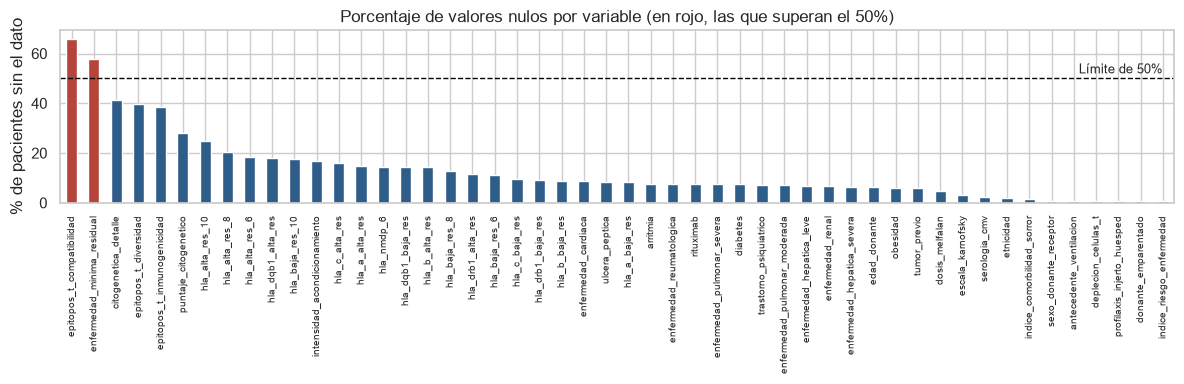

In [ ]:
# Revisión general de duplicados, tipos y porcentaje de nulos por variable.
print("Filas duplicadas:", df_raw.duplicated().sum(), "| IDs repetidos:", df_raw["ID"].duplicated().sum())
print("Variables categóricas:", df_raw.select_dtypes(exclude="number").shape[1], "| numéricas:", df_raw.select_dtypes("number").shape[1])
nulos_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
nulos_pct[nulos_pct > 0].rename(index=NOMBRES).plot(kind="bar", ax=ax, color=[ROJO if v > 50 else AZUL for v in nulos_pct[nulos_pct > 0]])
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.text(len(nulos_pct[nulos_pct > 0]) - 1, 52, "Límite de 50%", ha="right", fontsize=9)
ax.set_ylabel("% de pacientes sin el dato")
ax.set_title("Porcentaje de valores nulos por variable (en rojo, las que superan el 50%)")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
guardar_figura("nulos_variables", RUN_DATOS)

Análisis: no hay filas ni pacientes duplicados. Dos variables superan el 50% de nulos y se eliminan: epitopos_t_compatibilidad (66.0%) y enfermedad_minima_residual (57.6%). Les siguen citogenetica_detalle (41.4%), epitopos_t_diversidad y epitopos_t_inmunogenicidad (cerca de 39%) y las 17 variables HLA (entre 8% y 25%). Todas estas son variables genéticas, es decir, resultados de pruebas de laboratorio sobre la enfermedad o sobre qué tan compatibles son el paciente y el donante. Entre las clínicas, la que más nulos tiene es la intensidad del acondicionamiento (16.6%).

## 3.2 Limpieza: de df_raw a df_clean

df_raw es el archivo tal como viene. df_clean es el resultado de tres reglas que se aplican fila por fila y no usan la variable objetivo

Nota: Las transformaciones realizadas son las siguientes

- Se eliminan las variables con más de 50% de nulos.
- En las variables genéticas, un nulo se marca como No aplica. Son 21 variables: las 17 de compatibilidad HLA, puntaje_citogenetico y citogenetica_detalle, y epitopos_t_diversidad y epitopos_t_inmunogenicidad. Todas son resultados de pruebas genéticas sobre la enfermedad o sobre qué tan compatibles son el paciente y el donante. Si el dato no está, lo más probable es que la prueba no se hizo o no correspondía al caso, así que llenarlo con un promedio inventaría un resultado genético.
- Se crean cinco variables nuevas: diferencia de edad entre donante y paciente, si el paciente es pediátrico, número de comorbilidades, si recibió irradiación corporal total y el índice de riesgo de la enfermedad agrupado en seis grupos (Bajo, Intermedio, Alto, Muy alto, No aplica y Pendiente).

Los nulos que quedan en las demás variables se llenan más adelante dentro del Pipeline, para que ese paso aprenda solo de df_train.

In [ ]:
COLUMNAS_ELIMINADAS = [NOMBRES[c] for c in df_raw.columns if df_raw[c].isna().mean() > 0.5]
VARIABLES_GENETICAS = sorted(v for v in [c for c in NOMBRES.values() if c.startswith(("hla_", "epitopos_t_"))]
                             + ["puntaje_citogenetico", "citogenetica_detalle"] if v not in COLUMNAS_ELIMINADAS)
COMORBILIDADES = ["trastorno_psiquiatrico", "diabetes", "arritmia", "enfermedad_renal", "enfermedad_pulmonar_severa",
                  "enfermedad_pulmonar_moderada", "enfermedad_hepatica_severa", "enfermedad_hepatica_leve", "obesidad",
                  "tumor_previo", "ulcera_peptica", "enfermedad_reumatologica", "enfermedad_cardiaca"]
GRUPO_RIESGO = {
    "Low": "Bajo", "Intermediate": "Intermedio", "Intermediate - TED AML case <missing cytogenetics": "Intermedio",
    "High": "Alto", "High - TED AML case <missing cytogenetics": "Alto", "Very high": "Muy alto",
    "N/A - non-malignant indication": "No aplica", "N/A - pediatric": "No aplica", "N/A - disease not classifiable": "No aplica",
    "TBD cytogenetics": "Pendiente", "Missing disease status": "Pendiente",
}

def limpiar_datos(df, columnas_eliminadas, variables_geneticas):
    df = df.rename(columns=NOMBRES).drop(columns=columnas_eliminadas, errors="ignore")
    for c in variables_geneticas:
        if c in df.columns:
            texto = df[c].map(lambda v: f"{v:g}" if isinstance(v, (int, float)) and not pd.isna(v) else v)
            df[c] = texto.fillna("No aplica").astype(str)
    df["dif_edad_donante"] = df["edad_donante"] - df["edad_paciente"]
    df["es_pediatrico"] = (df["edad_paciente"] < 18).astype(int)
    df["n_comorbilidades"] = (df[COMORBILIDADES] == "Yes").sum(axis=1)
    df["recibio_irradiacion"] = (df["irradiacion_corporal_total"] != "No TBI").astype(int)
    df["grupo_riesgo_enfermedad"] = df["indice_riesgo_enfermedad"].map(GRUPO_RIESGO).fillna(df["indice_riesgo_enfermedad"])
    return df.drop(columns=["indice_riesgo_enfermedad"])

df_clean = limpiar_datos(df_raw, COLUMNAS_ELIMINADAS, VARIABLES_GENETICAS)
print("Variables eliminadas por superar 50% de nulos:", COLUMNAS_ELIMINADAS)
print("Variables genéticas con nulos marcados como No aplica:", len(VARIABLES_GENETICAS))
print("Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad")
nulos_restantes = (df_clean.isna().mean() * 100).round(1)
print(f"Columnas: {df_raw.shape[1]} en df_raw y {df_clean.shape[1]} en df_clean | variables que aún tienen nulos: {(nulos_restantes > 0).sum()}")
(df_clean[VARIABLES_GENETICAS] == "No aplica").mean().mul(100).round(1).sort_values(ascending=False).rename("% marcado como No aplica").to_frame()

Variables eliminadas por superar 50% de nulos: ['enfermedad_minima_residual', 'epitopos_t_compatibilidad']
Variables genéticas con nulos marcados como No aplica: 21
Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad
Columnas: 60 en df_raw y 62 en df_clean | variables que aún tienen nulos: 28


,% marcado como No aplica
citogenetica_detalle,41.4
epitopos_t_diversidad,39.6
epitopos_t_inmunogenicidad,38.7
puntaje_citogenetico,28.0
hla_alta_res_10,24.9
hla_alta_res_8,20.2
hla_alta_res_6,18.3
hla_dqb1_alta_res,18.1
hla_baja_res_10,17.6
hla_c_alta_res,16.0


Análisis: df_clean conserva 62 columnas (60 originales, menos 2 eliminadas, más 5 nuevas, menos el índice de riesgo original, que queda reemplazado por su versión agrupada). Las 21 variables genéticas que siguen en el dataset ya no tienen nulos: cuando el dato no estaba, ahora dicen No aplica, entre 8% y 41% de los pacientes según la variable. Quedan 28 variables con nulos, casi todas con menos de 10%, que se imputan dentro del Pipeline.

# 4. Variable objetivo y partición de los datos

La pregunta original es de supervivencia: cuántos meses pasan hasta el evento, una variable continua parecida a una regresión. Ese planteamiento tiene un problema: a muchos pacientes se les dejó de observar sin haber tenido el evento (censura), así que no se conoce su tiempo real. Se convierte en una clasificación con una pregunta concreta: ¿el paciente tendrá un evento en los primeros 12 meses, sí o no?

Tres razones lo justifican. La decisión clínica es binaria (seguimiento intensivo o habitual). Casi todos los eventos ocurren en el primer año, como muestra la curva que se revisa en la siguiente celda. Y la censura se resuelve de forma limpia: solo se excluyen los pacientes sin evento que salieron del seguimiento antes de cumplir el año.

Pacientes con evento: 15,532 | mediana de meses hasta el evento: 5.8 | eventos dentro de 12 meses: 96.8%


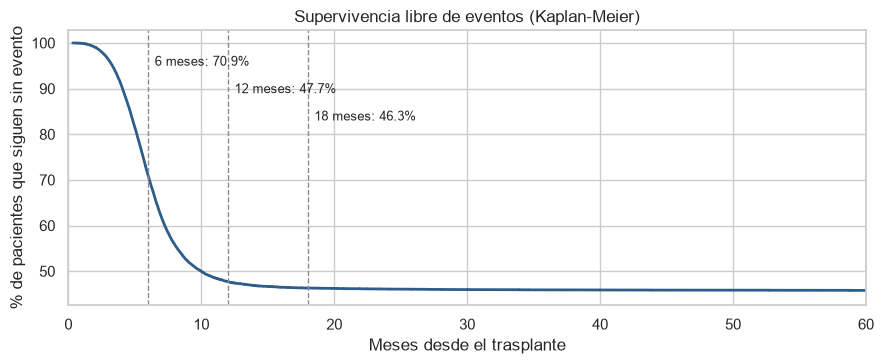

In [9]:
# Curva de Kaplan-Meier: probabilidad de seguir sin evento a lo largo del tiempo, teniendo en cuenta la censura.
def kaplan_meier(tiempo, evento):
    t, e = np.asarray(tiempo), np.asarray(evento)
    tiempos = np.unique(t[e == 1])
    en_riesgo = np.array([(t >= ti).sum() for ti in tiempos])
    eventos = np.array([((t == ti) & (e == 1)).sum() for ti in tiempos])
    return tiempos, np.cumprod(1 - eventos / en_riesgo)

tiempos, superv = kaplan_meier(df_clean["meses_hasta_evento"], df_clean["evento"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.step(tiempos, superv * 100, where="post", color=AZUL, linewidth=2)
for i, h in enumerate((6, 12, 18)):
    ax.axvline(h, color=GRIS, linestyle="--", linewidth=1)
    ax.text(h + 0.5, 95 - 6 * i, f"{h} meses: {superv[tiempos <= h][-1]:.1%}", fontsize=9)
ax.set_xlim(0, 60)
ax.set_xlabel("Meses desde el trasplante")
ax.set_ylabel("% de pacientes que siguen sin evento")
ax.set_title("Supervivencia libre de eventos (Kaplan-Meier)")
plt.tight_layout()
guardar_figura("kaplan_meier", RUN_DATOS)
con_evento = df_clean.loc[df_clean["evento"] == 1, "meses_hasta_evento"]
print(f"Pacientes con evento: {len(con_evento):,} | mediana de meses hasta el evento: {con_evento.median():.1f} | eventos dentro de 12 meses: {(con_evento <= 12).mean():.1%}")

Análisis: la curva cae rápido durante el primer año. A los 6 meses sigue sin evento el 70.9% de los pacientes, a los 12 meses el 47.7% y a los 18 meses el 46.3%, es decir, entre el mes 12 y el 18 casi no pasa nada. De los 15,532 pacientes que tuvieron el evento, el 96.8% lo tuvo dentro de los primeros 12 meses, con una mediana de 5.8 meses. Esto respalda usar 12 meses como horizonte.

In [10]:
# Variable objetivo: evento adverso en los primeros 12 meses. Se excluyen los pacientes sin evento que dejaron
# de ser observados antes de los 12 meses, porque no se sabe qué les pasó al cumplir el año.
HORIZONTE = 12
def construir_objetivo(df, h):
    utiles = ~((df["evento"] == 0) & (df["meses_hasta_evento"] < h))
    df_salida = df[utiles].copy()
    df_salida["evento_12m"] = ((df_salida["evento"] == 1) & (df_salida["meses_hasta_evento"] <= h)).astype(int)
    return df_salida

df_model = construir_objetivo(df_clean, HORIZONTE)
COLUMNAS_PROTEGIDAS = ["grupo_racial", "etnicidad"]
COLUMNAS_NO_PREDICTORAS = ["id", "evento", "meses_hasta_evento", "evento_12m"] + COLUMNAS_PROTEGIDAS
COLUMNAS_ENTRADA = [c for c in df_model.columns if c not in COLUMNAS_NO_PREDICTORAS]
print(f"df_model: {len(df_model):,} pacientes ({len(df_clean) - len(df_model)} excluidos por censura antes de 12 meses)")
print(f"Con evento en 12 meses: {df_model['evento_12m'].mean():.1%} | sin evento: {1 - df_model['evento_12m'].mean():.1%}")
print("Predictores:", len(COLUMNAS_ENTRADA))

df_model: 28,562 pacientes (238 excluidos por censura antes de 12 meses)
Con evento en 12 meses: 52.6% | sin evento: 47.4%
Predictores: 57


Análisis: solo 238 pacientes (0.8%) se excluyen por haber salido del seguimiento antes del año sin evento. df_model queda con 28,562 pacientes y 57 predictores, con 52.6% de pacientes con evento en 12 meses y 47.4% sin evento: las clases están casi balanceadas.

Partición de df_model en df_train (70%), df_val (15%) y df_test (15%), antes de cualquier paso que aprenda de los datos. El test.csv de la competencia no se usa porque solo trae 3 pacientes y no incluye el resultado; Kaggle guarda las respuestas en privado. El grupo racial y la etnicidad no se usan como predictores.

Por qué 70/15/15 con 28,562 pacientes:

- df_test (15%, unos 4,285 pacientes) es lo bastante grande para medir el AUC final con un margen de error pequeño; el intervalo de confianza de la sección 10 lo cuantifica.
- df_val (15%) hace falta porque varias decisiones se toman fuera de la validación cruzada: la forma de imputar, el uso de PCA y de SMOTE, la comprobación del modelo elegido y el umbral de alerta. Así df_test no se usa para ninguna decisión.
- df_train (70%, unos 20,000 pacientes) queda para la comparación de modelos y la búsqueda de hiperparámetros con validación cruzada.

La partición es estratificada por la variable objetivo (y por grupo racial), para que los tres conjuntos tengan la misma proporción de pacientes con evento y la misma mezcla de pacientes.

In [ ]:
estrato = df_model["evento_12m"].astype(str) + "_" + df_model["grupo_racial"]
df_temp, df_test = train_test_split(df_model, test_size=0.15, stratify=estrato, random_state=SEMILLA)
df_train, df_val = train_test_split(df_temp, test_size=0.15 / 0.85, stratify=estrato.loc[df_temp.index], random_state=SEMILLA)
X_train, X_val, X_test = df_train[COLUMNAS_ENTRADA], df_val[COLUMNAS_ENTRADA], df_test[COLUMNAS_ENTRADA]
y_train, y_val, y_test = df_train["evento_12m"], df_val["evento_12m"], df_test["evento_12m"]

# Comprobación de fuga: la regla de eliminar variables con más de 50% de nulos se calculó con todos los pacientes.
eliminadas_train = sorted(NOMBRES[c] for c in df_raw.columns if df_raw.loc[df_train.index, c].isna().mean() > 0.5)
print("Variables con más de 50% de nulos calculadas solo con df_train:", eliminadas_train,
      "| iguales a las eliminadas:", eliminadas_train == sorted(COLUMNAS_ELIMINADAS))

with mlflow.start_run(run_id=RUN_DATOS):
    mlflow.log_params({"horizonte_meses": HORIZONTE, "pacientes_modelo": len(df_model), "predictores": len(COLUMNAS_ENTRADA),
                       "pacientes_train": len(df_train), "pacientes_val": len(df_val), "pacientes_test": len(df_test),
                       "columnas_eliminadas": ", ".join(COLUMNAS_ELIMINADAS)})
    for nombre_conjunto, df_conjunto in [("df_train", df_train), ("df_val", df_val), ("df_test", df_test)]:
        mlflow.log_input(mlflow.data.from_pandas(df_conjunto, name=nombre_conjunto, targets="evento_12m"), context=nombre_conjunto)

pd.DataFrame({"pacientes": [len(df_train), len(df_val), len(df_test)],
              "% con evento en 12 meses": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
              "% sin evento": [round((1 - y.mean()) * 100, 2) for y in (y_train, y_val, y_test)]},
             index=["df_train", "df_val", "df_test"])

Variables con más de 50% de nulos calculadas solo con df_train: ['enfermedad_minima_residual', 'epitopos_t_compatibilidad'] | iguales a las eliminadas: True


,pacientes,% con evento en 12 meses,% sin evento
df_train,19992,52.62,47.38
df_val,4285,52.65,47.35
df_test,4285,52.65,47.35


Análisis: los tres conjuntos tienen la misma proporción de eventos (52.6% con evento y 47.4% sin evento) gracias a la estratificación. La comprobación de fuga da el resultado esperado: calculada solo con df_train, la regla de más de 50% de nulos elimina las mismas dos variables (enfermedad_minima_residual y epitopos_t_compatibilidad), así que haberla calculado con todos los pacientes no le pasa información de df_val ni de df_test al modelo. df_test (4,285 pacientes) no se vuelve a tocar hasta la sección 10.

# 5. Análisis exploratorio

**Nota Aclaratoria:** Todo el análisis usa solo df_train.

## 5.1 Edad del paciente y del donante

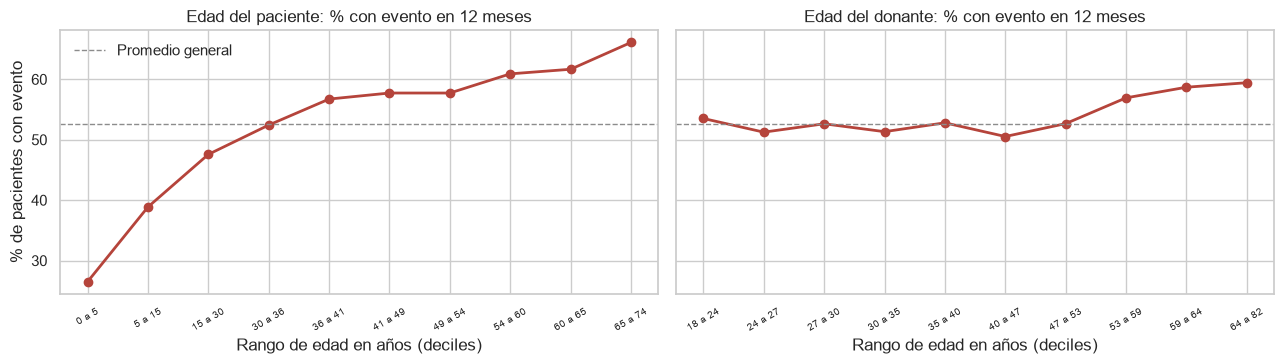

In [ ]:
# Porcentaje de pacientes con evento en 12 meses por tramos de edad del paciente y del donante (solo df_train).
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, titulo in zip(axes, ["edad_paciente", "edad_donante"], ["Edad del paciente", "Edad del donante"]):
    decil = pd.qcut(df_train[col], 10, duplicates="drop")
    tasa = y_train.groupby(decil.values, observed=True).mean()
    ax.plot(range(len(tasa)), tasa.values * 100, marker="o", color=ROJO, linewidth=2)
    ax.set_xticks(range(len(tasa)))
    ax.set_xticklabels([f"{iv.left:.0f} a {iv.right:.0f}" for iv in tasa.index], fontsize=7, rotation=30)
    ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1, label="Promedio general")
    ax.set_title(f"{titulo}: % con evento en 12 meses")
    ax.set_xlabel("Rango de edad en años (deciles)")
axes[0].set_ylabel("% de pacientes con evento")
axes[0].legend(frameon=False)
plt.tight_layout()
guardar_figura("edad", RUN_DATOS)

Análisis: la edad del paciente es uno de los factores más claros. En los niños de 0 a 5 años solo el 26% tiene un evento en el primer año, en el rango de 30 a 36 años ya está en el promedio (52%) y en los mayores de 65 llega a 66%. La edad del donante pesa mucho menos: la curva se mantiene alrededor del promedio hasta los 53 años y solo sube a 57% a 59% con donantes mayores. Por eso se creó la variable de diferencia de edad entre donante y paciente.

## 5.2 Variables clínicas principales

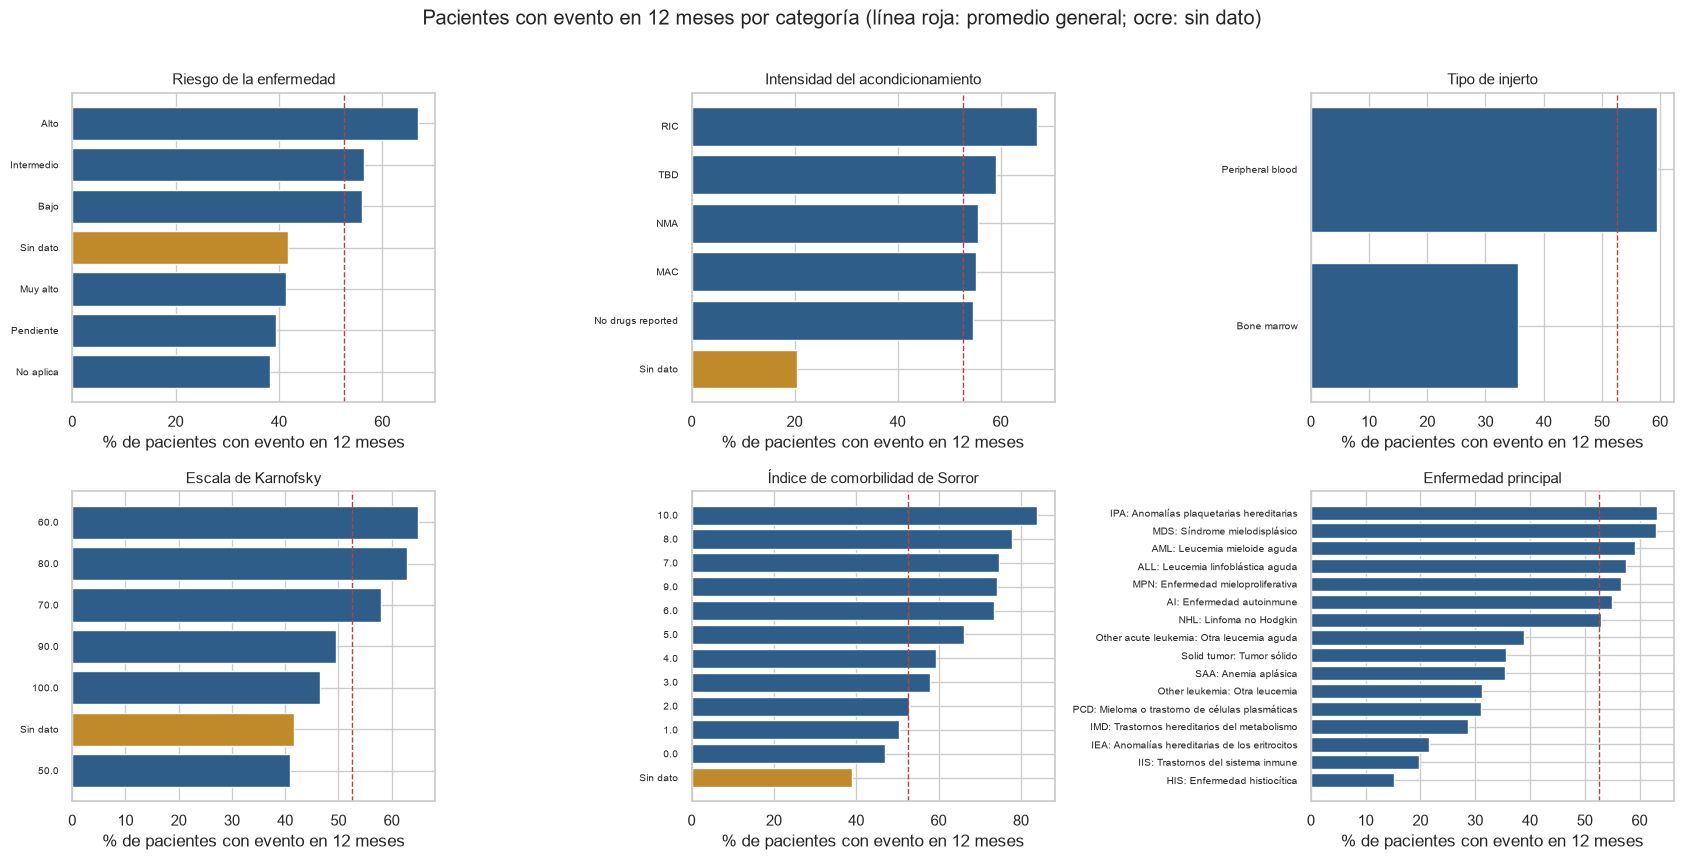

In [13]:
# Porcentaje con evento en 12 meses según la categoría de seis variables clínicas (categorías con 50 o más pacientes).
paneles = {"grupo_riesgo_enfermedad": "Riesgo de la enfermedad", "intensidad_acondicionamiento": "Intensidad del acondicionamiento",
           "tipo_injerto": "Tipo de injerto", "escala_karnofsky": "Escala de Karnofsky",
           "indice_comorbilidad_sorror": "Índice de comorbilidad de Sorror", "enfermedad_principal": "Enfermedad principal"}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col, titulo) in zip(axes.ravel(), paneles.items()):
    serie = df_train[col].astype(object).where(df_train[col].notna(), "Sin dato").astype(str)
    if col == "enfermedad_principal":
        serie = serie.map(etiqueta_enfermedad)
    resumen = y_train.groupby(serie.values).agg(["mean", "size"])
    resumen = resumen[resumen["size"] >= 50].sort_values("mean")
    ax.barh(resumen.index, resumen["mean"] * 100, color=[OCRE if i == "Sin dato" else AZUL for i in resumen.index])
    ax.axvline(y_train.mean() * 100, color=ROJO, linestyle="--", linewidth=1)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("% de pacientes con evento en 12 meses")
    ax.tick_params(axis="y", labelsize=7)
plt.suptitle("Pacientes con evento en 12 meses por categoría (línea roja: promedio general; ocre: sin dato)", y=1.01)
plt.tight_layout()
guardar_figura("variables_clinicas", RUN_DATOS)

Análisis: la mayoría de las variables separan bien el riesgo y en la dirección esperada. Un índice de riesgo alto lleva al 66% con evento, el acondicionamiento de intensidad reducida (RIC) al 67% frente a 55% del intenso (MAC), la sangre periférica al 60% frente a 35% de la médula ósea, y el índice de Sorror sube de forma casi continua de 47% con 0 puntos a 84% con 10. Hay dos excepciones: la categoría Muy alto del índice de riesgo queda por debajo del promedio (41%), y en la escala de Karnofsky el valor 50 tiene menos eventos que 60 u 80, así que esa escala no sigue un orden perfecto.

Lo más llamativo son las barras ocre: los pacientes sin dato quedan por debajo del promedio en las cuatro variables donde aparecen, y en la intensidad del acondicionamiento y el índice de Sorror tienen menos riesgo que cualquier categoría real. Sin dato de intensidad, solo el 20% tiene evento. Eso no puede ser un efecto clínico del dato vacío, así que se investiga en las secciones 5.4 y 5.5.

## 5.3 Compatibilidad HLA y PCA

HLA son marcadores genéticos que las defensas del cuerpo usan para reconocer qué es propio y qué es ajeno. Entre más se parezcan los del donante y los del paciente, menor es el riesgo de rechazo. El dataset trae 17 variables que cuentan cuántas coincidencias hay entre paciente y donante, medidas con dos niveles de detalle (baja y alta resolución).

Correlación media entre pares de variables HLA: 0.763 | mínima: 0.494
Pacientes con hla_alta_res_8 en No aplica: 20.1% | % con evento: 51.7% frente a 52.9% con el dato


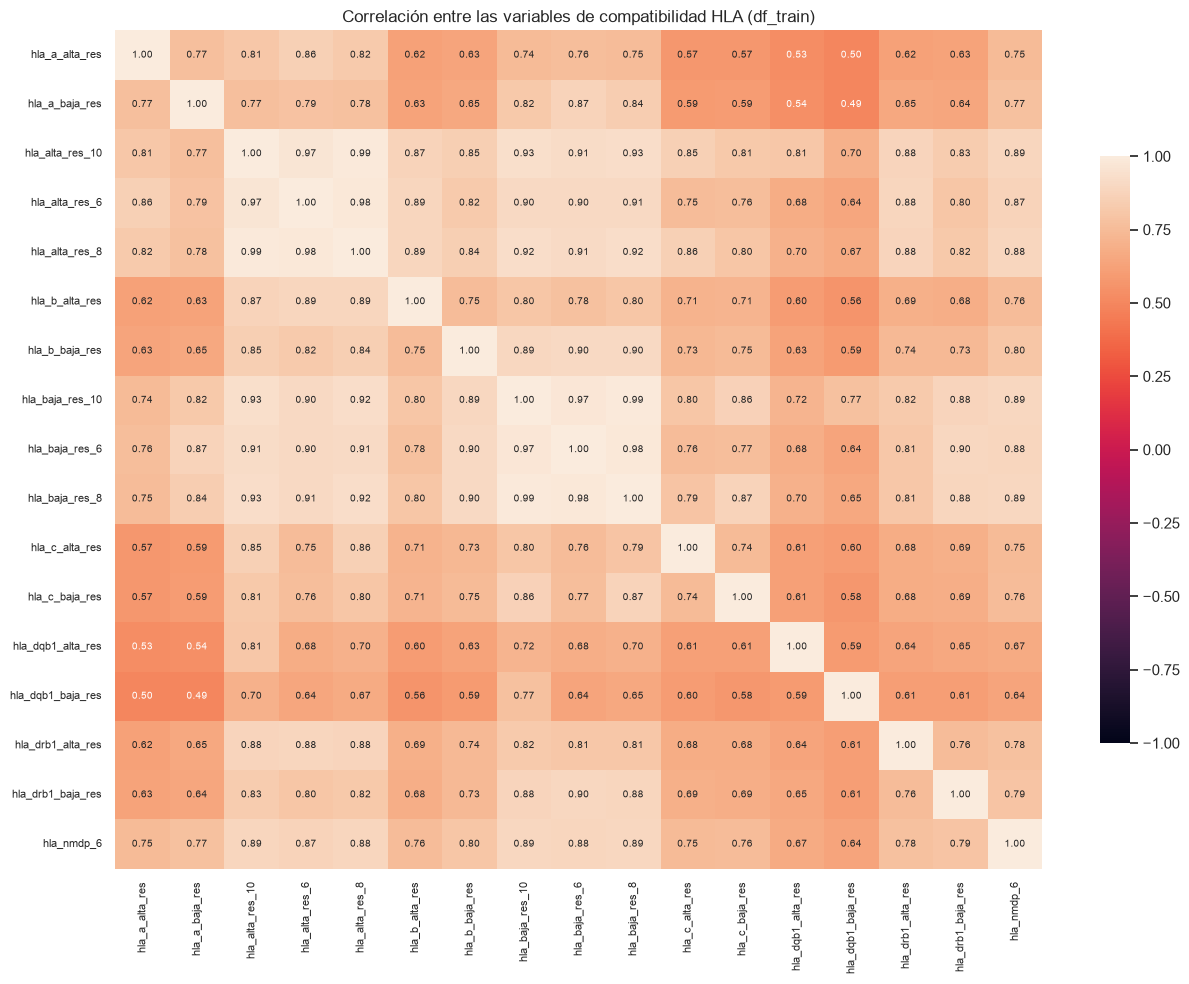

In [14]:
# Las 17 variables HLA miden qué tan compatibles son paciente y donante. Correlación entre ellas con su valor numérico.
COLUMNAS_HLA = sorted([c for c in df_clean.columns if c.startswith("hla_")])
hla_numerico = df_train[COLUMNAS_HLA].apply(pd.to_numeric, errors="coerce")
corr_hla = hla_numerico.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_hla, annot=True, fmt=".2f", annot_kws={"size": 7}, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.tick_params(labelsize=8)
ax.set_title("Correlación entre las variables de compatibilidad HLA (df_train)")
plt.tight_layout()
guardar_figura("hla_correlacion", RUN_DATOS)
triu = corr_hla.where(np.triu(np.ones(corr_hla.shape, dtype=bool), k=1)).stack()
print(f"Correlación media entre pares de variables HLA: {triu.mean():.3f} | mínima: {triu.min():.3f}")
sin_hla = df_train["hla_alta_res_8"] == "No aplica"
print(f"Pacientes con hla_alta_res_8 en No aplica: {sin_hla.mean():.1%} | % con evento: {y_train[sin_hla].mean():.1%} "
      f"frente a {y_train[~sin_hla].mean():.1%} con el dato")

Análisis: las variables HLA son casi copias unas de otras, con una correlación media de 0.763 entre pares y ninguna por debajo de 0.49. Las que resumen varios genes (por ejemplo hla_alta_res_8 y hla_alta_res_10) llegan a 0.99. Tener 17 versiones de la misma información infla el número de columnas sin aportar mucho, lo que justifica aplicar PCA a este bloque. El 20.1% de los pacientes no tiene el dato de hla_alta_res_8 (ahora No aplica) y su porcentaje con evento (51.7%) es casi igual al de quienes sí lo tienen (52.9%).

Columnas One-Hot del bloque HLA: 88 | primer componente: 41.6% | componentes para el 95%: 28


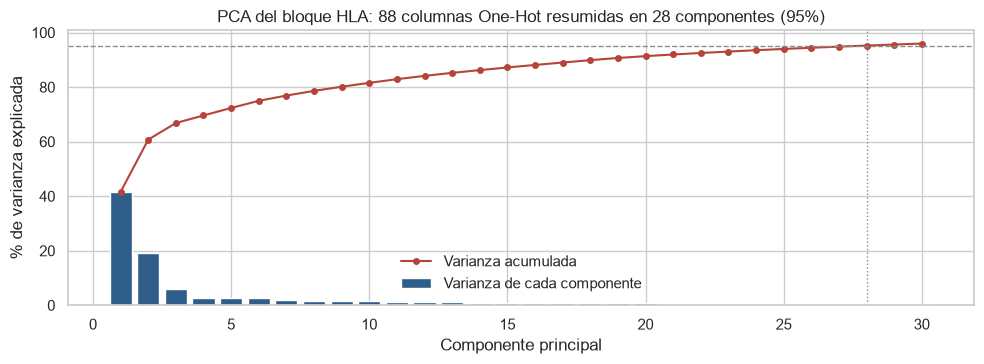

In [15]:
# PCA sobre el bloque HLA codificado con One-Hot (cada valor, incluido No aplica, es una columna).
pipelinePcaHLA = Pipeline([("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)),
                           ("pca", PCA(random_state=SEMILLA))]).fit(df_train[COLUMNAS_HLA])
varianza = pipelinePcaHLA.named_steps["pca"].explained_variance_ratio_
varianza_acum = np.cumsum(varianza)
N_COMPONENTES_HLA = int(np.searchsorted(varianza_acum, 0.95) + 1)
n_onehot = len(varianza)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, 31), varianza[:30] * 100, color=AZUL, label="Varianza de cada componente")
ax.plot(range(1, 31), varianza_acum[:30] * 100, color=ROJO, marker="o", markersize=4, label="Varianza acumulada")
ax.axhline(95, color=GRIS, linestyle="--", linewidth=1)
ax.axvline(N_COMPONENTES_HLA, color=GRIS, linestyle=":", linewidth=1)
ax.set_xlabel("Componente principal")
ax.set_ylabel("% de varianza explicada")
ax.set_title(f"PCA del bloque HLA: {n_onehot} columnas One-Hot resumidas en {N_COMPONENTES_HLA} componentes (95%)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("hla_pca", RUN_DATOS)
print(f"Columnas One-Hot del bloque HLA: {n_onehot} | primer componente: {varianza[0]:.1%} | componentes para el 95%: {N_COMPONENTES_HLA}")

Análisis: al codificar con One-Hot, el bloque HLA pasa a 88 columnas. El primer componente ya explica el 41.6% de la varianza y el segundo lleva el acumulado a cerca del 60%; con 28 componentes se conserva el 95%. Se reduce el bloque a menos de un tercio de sus columnas sin perder casi información. En el Pipeline no se fija el número 28: se pide conservar el 95% de la varianza y cada ajuste calcula cuántos componentes necesita con sus propios datos.

## 5.4 Quién tiene datos vacíos

Después de la limpieza, las variables genéticas ya no tienen nulos. Esta sección revisa las demás: cuántas variables vacías tiene cada paciente y en qué segmentos se concentran.

,pacientes,variables_vacias_promedio,pct_sin_intensidad
grupo_edad,,,
Adulto,15329,1.34,7.4
Pediátrico,4663,1.69,47.9


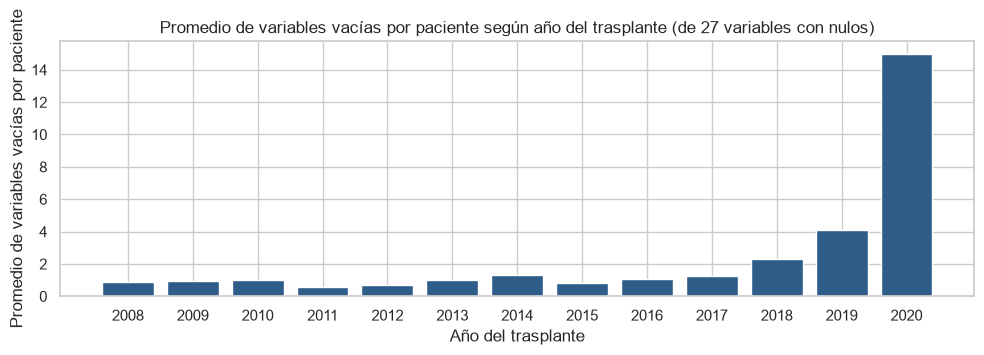

In [16]:
# ¿Quién tiene datos vacíos? Se cuentan las variables no genéticas que siguen vacías en cada paciente.
COLUMNAS_CON_NULOS = [c for c in COLUMNAS_ENTRADA if df_train[c].isna().any()]
df_eda = df_train.copy()
df_eda["n_vacias"] = df_eda[COLUMNAS_CON_NULOS].isna().sum(axis=1)
df_eda["sin_intensidad"] = df_eda["intensidad_acondicionamiento"].isna()
df_eda["grupo_edad"] = np.where(df_eda["es_pediatrico"] == 1, "Pediátrico", "Adulto")
por_anio = df_eda.groupby("anio_trasplante")["n_vacias"].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(por_anio.index.astype(str), por_anio.values, color=AZUL)
ax.set_xlabel("Año del trasplante")
ax.set_ylabel("Promedio de variables vacías por paciente")
ax.set_title(f"Promedio de variables vacías por paciente según año del trasplante (de {len(COLUMNAS_CON_NULOS)} variables con nulos)")
plt.tight_layout()
guardar_figura("nulos_anio", RUN_DATOS)
df_eda.groupby("grupo_edad").agg(pacientes=("id", "size"), variables_vacias_promedio=("n_vacias", "mean"),
                                 pct_sin_intensidad=("sin_intensidad", "mean")).assign(pct_sin_intensidad=lambda d: (d["pct_sin_intensidad"] * 100).round(1)).round(2)

Análisis: entre 2008 y 2017 cada paciente tiene en promedio alrededor de una variable vacía, de las 27 que todavía pueden tener nulos. A partir de 2018 el número sube: 2.3 en 2018 y 4.1 en 2019. La barra de 2020 llega a 15, pero ese año solo tiene 2 pacientes en df_train (sección 5.5), así que no se puede leer como tendencia. Los vacíos se concentran en los registros más recientes, lo que apunta a formularios que todavía no se habían completado cuando se armó el registro. La tabla muestra además que a los pacientes pediátricos les falta la intensidad del acondicionamiento en el 47.9% de los casos, frente a 7.4% en los adultos.

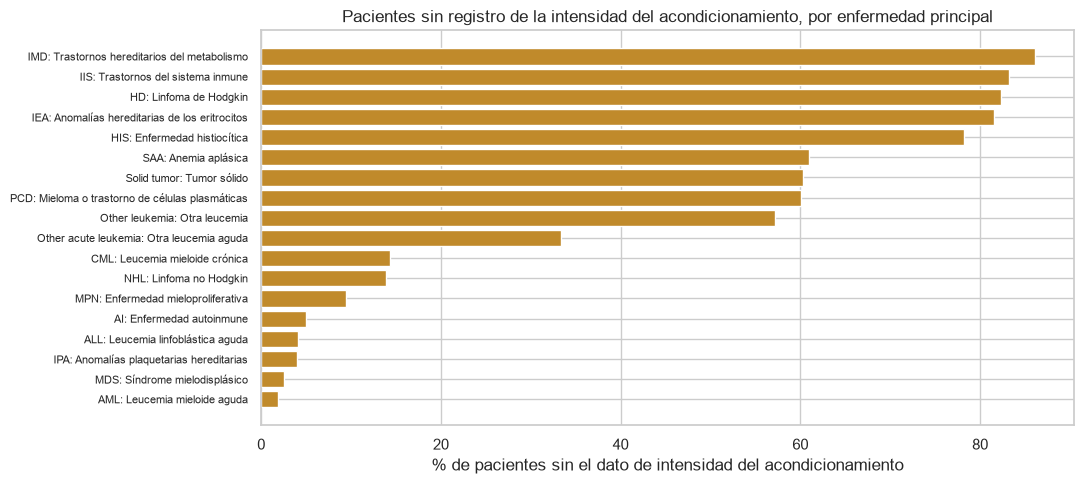

In [17]:
# La variable no genética con más nulos es la intensidad del acondicionamiento (la quimioterapia o radiación previa al trasplante).
# Se mide qué porcentaje de pacientes de cada enfermedad no tiene ese dato registrado.
por_enf = df_eda.groupby("enfermedad_principal")["sin_intensidad"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh([etiqueta_enfermedad(c) for c in por_enf.index], por_enf.values, color=OCRE)
ax.set_xlabel("% de pacientes sin el dato de intensidad del acondicionamiento")
ax.set_title("Pacientes sin registro de la intensidad del acondicionamiento, por enfermedad principal")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
guardar_figura("nulos_enfermedad", RUN_DATOS)

Análisis: la falta del dato de intensidad no es aleatoria, depende de la enfermedad. Les falta al 78% o más de los pacientes con enfermedades hereditarias o no malignas (trastornos del metabolismo, del sistema inmune, de los eritrocitos y la enfermedad histiocítica) y también al 82% de los pocos casos de linfoma de Hodgkin. En cambio, en las leucemias agudas y el síndrome mielodisplásico casi siempre está (menos de 5% sin dato). Estas son, además, las enfermedades de menor riesgo en la sección 5.2.

## 5.5 Datos vacíos y seguimiento en el tiempo

In [18]:
# ¿Los vacíos se deben a pacientes que dejan de asistir con el tiempo? Se compara el seguimiento de los pacientes
# sin evento según cuántas variables tienen vacías, y el % con evento con y sin el dato de intensidad.
df_censurados = df_eda[df_eda["evento"] == 0]
seguimiento = df_censurados.groupby(pd.cut(df_censurados["n_vacias"], [-1, 0, 2, 5, 60], labels=["0", "1 a 2", "3 a 5", "6 o más"]),
                                    observed=True)["meses_hasta_evento"].agg(["size", "median"]).rename(
    columns={"size": "pacientes sin evento", "median": "mediana de meses de seguimiento"})
display(seguimiento.round(1))
tabla_intensidad = df_eda.groupby(["grupo_edad", "sin_intensidad"])["evento_12m"].agg(["size", "mean"])
tabla_intensidad.columns = ["pacientes", "% con evento en 12 meses"]
tabla_intensidad["% con evento en 12 meses"] = (tabla_intensidad["% con evento en 12 meses"] * 100).round(1)
tabla_intensidad

,pacientes sin evento,mediana de meses de seguimiento
n_vacias,,
0,4337,39.5
1 a 2,3189,37.8
3 a 5,931,35.9
6 o más,658,27.3


pacientes  % con evento en 12 meses
grupo_edad sin_intensidad                                     
Adulto     False               14198                      61.0
           True                 1131                      23.6
Pediátrico False                2428                      48.4
           True                 2235                      18.9

Análisis: los vacíos no vienen de pacientes que dejan de asistir. Los pacientes sin evento tienen un seguimiento de 36 a 40 meses en mediana, tengan 0 o 5 variables vacías. El grupo con 6 o más vacías tiene menos seguimiento (27.3 meses), lo que coincide con la gráfica anterior: los trasplantes de 2019 y 2020 son los que más vacíos tienen y también los que llevan menos tiempo de observación.

El efecto sobre el riesgo es grande: en los adultos, el 61.0% de quienes tienen el dato de intensidad tuvo un evento, frente a 23.6% de quienes no lo tienen. En los niños, 48.4% frente a 18.9%. El vacío funciona como una señal de que el paciente pertenece a un grupo de bajo riesgo, no como un dato clínico.

Riesgo por año del trasplante. La sección 5.4 mostró que los registros más recientes tienen más datos vacíos. Aquí se revisa si el porcentaje de pacientes con evento también cambia con el año.

,pacientes,% con evento en 12 meses,variables_vacias_promedio
anio_trasplante,,,
2008,1761,59.3,0.9
2009,359,68.0,0.9
2010,271,63.8,1.0
2011,426,62.2,0.6
2012,1105,55.6,0.7
2013,1303,50.1,1.0
2014,785,46.1,1.3
2015,1566,57.8,0.8
2016,3534,51.4,1.1


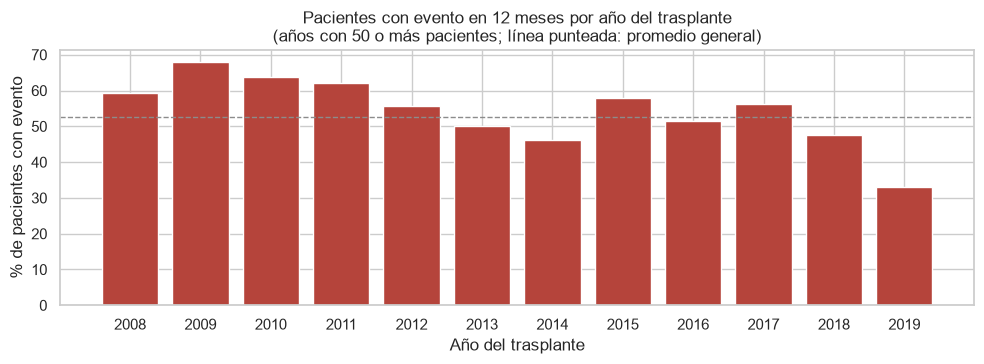

In [19]:
# Porcentaje con evento en 12 meses por año del trasplante (solo df_train), junto al promedio de variables vacías de la sección 5.4.
# La gráfica muestra los años con 50 o más pacientes; la tabla los muestra todos.
riesgo_anio = df_eda.groupby("anio_trasplante").agg(pacientes=("id", "size"), pct_evento=("evento_12m", "mean"),
                                                    variables_vacias_promedio=("n_vacias", "mean"))
riesgo_anio["pct_evento"] = riesgo_anio["pct_evento"] * 100
grafica_anio = riesgo_anio[riesgo_anio["pacientes"] >= 50]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(grafica_anio.index.astype(str), grafica_anio["pct_evento"], color=ROJO)
ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1)
ax.set_xlabel("Año del trasplante")
ax.set_ylabel("% de pacientes con evento")
ax.set_title("Pacientes con evento en 12 meses por año del trasplante\n(años con 50 o más pacientes; línea punteada: promedio general)")
plt.tight_layout()
guardar_figura("riesgo_anio", RUN_DATOS)
riesgo_anio.rename(columns={"pct_evento": "% con evento en 12 meses"}).round(1)

Análisis: hasta 2017 el porcentaje con evento sube y baja entre 46% y 68% sin una tendencia clara (59.3% en 2008, 46.1% en 2014 y 56.1% en 2017). En 2018 baja a 47.5% y en 2019 a 33.0%, los mismos años en que más crecen los datos vacíos (2.3 y 4.1 variables por paciente). 2020 queda fuera de la gráfica porque solo tiene 2 pacientes. Con estos datos no se puede saber si la caída de los últimos años se debe a mejores tratamientos o a registros todavía incompletos, así que el efecto del año que aprenda el modelo debe leerse con cuidado (sección 12).

## 5.6 Conclusiones del análisis exploratorio

- El riesgo depende sobre todo de la edad, la comorbilidad (Sorror), el estado funcional (Karnofsky), el tipo de injerto, la intensidad del acondicionamiento y la enfermedad.
- Las 17 variables HLA son muy redundantes y se pueden resumir con PCA.
- Los datos vacíos tienen un patrón claro: se concentran en pacientes pediátricos, en varias enfermedades hereditarias o no malignas (no en todas: a las anomalías plaquetarias hereditarias casi nunca les falta la intensidad del acondicionamiento) y en los trasplantes de 2018 y 2019. No se deben a pacientes que abandonan el seguimiento.
- Un vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. La sección 6 compara dos formas de imputar para evitarlo.
- El porcentaje con evento baja en 2018 y 2019, los años con más datos vacíos. El año del trasplante puede reflejar tanto cambios en los tratamientos como registros incompletos.

# 6. Preparación de datos: Pipeline, imputación y reducción de dimensión

Todo el preprocesamiento se arma con clases estándar de scikit-learn dentro de un Pipeline:

- Bloque HLA: OneHotEncoder (cada valor, incluido No aplica, es una columna) y PCA que conserva el 95% de la varianza.
- Numéricas: SimpleImputer con la mediana y StandardScaler. El escalado es necesario para LogisticRegression, KNN y PCA; a los modelos de árboles no les afecta.
- Categóricas: SimpleImputer y OneHotEncoder, agrupando las categorías con menos de 20 pacientes.

Por qué todo va dentro del Pipeline: cada uno de estos pasos aprende algo de los datos (la mediana, la media y la desviación del escalado, las categorías y los componentes del PCA). Si se ajustaran una sola vez con todos los pacientes antes de la validación cruzada, esos valores incluirían a los pacientes con los que después se mide el modelo, y el resultado saldría mejor de lo real (fuga de información). Dentro del Pipeline, en cada pliegue y en cada ajuste los pasos aprenden solo de los datos de entrenamiento y después se aplican tal cual a los de validación.

In [20]:
# HLA: One-Hot y PCA. Numéricas: mediana y escalado. Categóricas: valor más frecuente y One-Hot.
VARIANZA_PCA_HLA = 0.95
COLUMNAS_CATEGORICAS = [c for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA and not pd.api.types.is_numeric_dtype(df_model[c])]
COLUMNAS_NUMERICAS = [c for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA + COLUMNAS_CATEGORICAS]

def crear_pipeline(estimador, imputacion_categorica="most_frequent", pca_hla=True, pca_global=None):
    pasos_hla = [("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]
    if pca_hla:
        pasos_hla.append(("pca", PCA(n_components=VARIANZA_PCA_HLA, svd_solver="full", random_state=SEMILLA)))
    columnTransformer = ColumnTransformer([
        ("hla", Pipeline(pasos_hla), COLUMNAS_HLA),
        ("num", Pipeline([("simpleImputer", SimpleImputer(strategy="median")), ("standardScaler", StandardScaler())]), COLUMNAS_NUMERICAS),
        ("cat", Pipeline([("simpleImputer", SimpleImputer(strategy=imputacion_categorica, fill_value="No informado")),
                          ("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]),
         COLUMNAS_CATEGORICAS),
    ])
    pasos = [("columnTransformer", columnTransformer)]
    if pca_global is not None:
        pasos.append(("pca", PCA(n_components=pca_global, svd_solver="full", random_state=SEMILLA)))
    pasos.append(("modelo", estimador))
    return Pipeline(pasos)

# Configuraciones de partida: se usan en los experimentos de las secciones 6 y 7, antes de ajustar hiperparámetros.
def lr_partida():
    return LogisticRegression(max_iter=3000, C=0.1)


def xgb_partida():
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=HILOS_POR_MODELO, random_state=SEMILLA)


print(f"Predictores: {len(COLUMNAS_HLA)} HLA, {len(COLUMNAS_NUMERICAS)} numéricos y {len(COLUMNAS_CATEGORICAS)} categóricos")
print("Columnas que recibe el modelo:", crear_pipeline(LogisticRegression())[:-1].fit_transform(X_train).shape[1])
print("Pasos del Pipeline:", [nombre for nombre, _ in crear_pipeline(XGBClassifier()).steps])

Predictores: 17 HLA, 9 numéricos y 31 categóricos


Columnas que recibe el modelo: 181
Pasos del Pipeline: ['columnTransformer', 'modelo']


Experimento de imputación. En el análisis exploratorio se vio que un dato vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. Se comparan dos estrategias de SimpleImputer para las categóricas: constant, que crea la categoría No informado, y most_frequent, que pone el valor más común.

In [21]:
# Cambio de riesgo con vacíos: diferencia en el riesgo promedio cuando, a pacientes completos de df_val, se les borran
# la intensidad del acondicionamiento, la escala de Karnofsky y el índice de Sorror.
X_val_completos = X_val[X_val[["intensidad_acondicionamiento", "escala_karnofsky", "indice_comorbilidad_sorror"]].notna().all(axis=1)]
X_val_borrados = X_val_completos.copy()
X_val_borrados["intensidad_acondicionamiento"] = pd.Series(np.nan, index=X_val_borrados.index, dtype=object)
X_val_borrados[["escala_karnofsky", "indice_comorbilidad_sorror"]] = np.nan
filas = []
with iniciar_run("experimento_imputacion") as run:
    for nombre_modelo, crear_estimador in [("LogisticRegression", lr_partida), ("XGBClassifier", xgb_partida)]:
        for estrategia in ["constant", "most_frequent"]:
            pipeline = crear_pipeline(crear_estimador(), imputacion_categorica=estrategia).fit(X_train, y_train)
            auc = roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1])
            cambio = pipeline.predict_proba(X_val_borrados)[:, 1].mean() - pipeline.predict_proba(X_val_completos)[:, 1].mean()
            registrar_variante(f"{nombre_modelo} | {estrategia}", {"modelo": nombre_modelo, "imputacion_categorica": estrategia},
                               {"auc_val": auc, "cambio_riesgo_vacios_puntos": cambio * 100})
            filas.append({"modelo": nombre_modelo, "SimpleImputer": estrategia, "AUC en df_val": auc,
                          "cambio de riesgo con vacíos (puntos %)": cambio * 100})
    tabla_imputacion = pd.DataFrame(filas).set_index(["modelo", "SimpleImputer"]).round(4)
    registrar_tabla(run.info.run_id, tabla_imputacion, "experimento_imputacion")
print(f"Pacientes completos de df_val usados para medir el cambio: {len(X_val_completos):,}")
tabla_imputacion

Pacientes completos de df_val usados para medir el cambio: 3,447


AUC en df_val  \
modelo             SimpleImputer                  
LogisticRegression constant              0.7397   
                   most_frequent         0.7369   
XGBClassifier      constant              0.7407   
                   most_frequent         0.7378   

                                  cambio de riesgo con vacíos (puntos %)  
modelo             SimpleImputer                                          
LogisticRegression constant                                     -21.7501  
                   most_frequent                                 -5.4370  
XGBClassifier      constant                                     -31.3937  
                   most_frequent                                 -6.6878

Análisis: con la categoría No informado (constant) el modelo aprende que el vacío significa bajo riesgo: al borrarles los tres datos a los pacientes completos, su riesgo promedio cae 21.8 puntos con LogisticRegression y 31.4 con XGBClassifier. Con most_frequent la caída se reduce a 5.4 y 6.7 puntos, y el AUC solo baja 0.003 en ambos modelos.

Se elige most_frequent: cuesta muy poco en AUC y reduce mucho el premio a los formularios incompletos, aunque no lo elimina del todo. Parte de la caída que queda se explica porque el valor más común no siempre es el que tenía el paciente: la intensidad más común es MAC, que en la sección 5.2 tiene menos eventos que RIC.

Experimento de reducción de dimensión: se compara no usar PCA, usarlo solo en el bloque HLA y usarlo sobre todas las columnas.

In [22]:
# Reducción de dimensión con LogisticRegression en df_val: sin PCA, PCA solo en HLA y PCA sobre todas las columnas.
filas = []
with iniciar_run("experimento_pca") as run:
    for variante, kw in [("Sin PCA", dict(pca_hla=False)), ("PCA solo en HLA (95% de varianza)", dict(pca_hla=True)),
                         ("PCA sobre todas las columnas (95% de varianza)", dict(pca_hla=True, pca_global=0.95))]:
        pipeline = crear_pipeline(lr_partida(), **kw).fit(X_train, y_train)
        columnas = pipeline[:-1].transform(X_val.head(1)).shape[1]
        auc = roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1])
        registrar_variante(variante, {"variante": variante, "modelo": "LogisticRegression"}, {"auc_val": auc, "columnas_modelo": columnas})
        filas.append({"variante": variante, "columnas que recibe el modelo": columnas, "AUC en df_val": auc})
    tabla_pca = pd.DataFrame(filas).set_index("variante").round(4)
    registrar_tabla(run.info.run_id, tabla_pca, "experimento_pca")
tabla_pca

,columnas que recibe el modelo,AUC en df_val
variante,,
Sin PCA,241,0.7377
PCA solo en HLA (95% de varianza),181,0.7369
PCA sobre todas las columnas (95% de varianza),72,0.7315


Análisis: aplicar PCA solo al bloque HLA reduce las columnas de 241 a 181 con una pérdida mínima de AUC (de 0.7377 a 0.7369); con df_train completo, el 95% de la varianza se alcanza con los mismos 28 componentes de la sección 5.3. Aplicarlo sobre todas las columnas las baja a 72, pero el AUC cae a 0.7315, porque mezcla variables clínicas que sí aportan información distinta. Se usa PCA solo en el bloque HLA.

# 7. Balanceo de clases: prueba con SMOTE

Las clases están casi balanceadas (52.6% con evento y 47.4% sin evento). Se hace una sola prueba con SMOTE, que crea pacientes sintéticos de la clase minoritaria a partir de sus vecinos más cercanos hasta igualar las dos clases, para ver si mejora o empeora el resultado frente a no balancear. SMOTE va dentro del Pipeline, después del preprocesamiento, así que solo actúa al entrenar y nunca sobre df_val.

In [ ]:
# SMOTE va en un Pipeline de imbalanced-learn entre el preprocesamiento y el modelo: solo se aplica al entrenar.
print(f"Proporción en df_train: {y_train.mean():.1%} con evento y {1 - y_train.mean():.1%} sin evento")
filas = []
with iniciar_run("experimento_smote") as run:
    for nombre_modelo, crear_estimador in [("LogisticRegression", lr_partida), ("XGBClassifier", xgb_partida)]:
        variantes = {
            "sin SMOTE": crear_pipeline(crear_estimador()),
            "con SMOTE": PipelineImblearn([("columnTransformer", crear_pipeline(crear_estimador()).named_steps["columnTransformer"]),
                                           ("smote", SMOTE(random_state=SEMILLA)), ("modelo", crear_estimador())]),
        }
        for estrategia, pipeline in variantes.items():
            prob = pipeline.fit(X_train, y_train).predict_proba(X_val)[:, 1]
            fila = {"modelo": nombre_modelo, "estrategia": estrategia, "AUC": roc_auc_score(y_val, prob),
                    "F1 macro": f1_score(y_val, prob >= 0.5, average="macro"),
                    "balanced accuracy": balanced_accuracy_score(y_val, prob >= 0.5), "recall del evento": recall_score(y_val, prob >= 0.5)}
            registrar_variante(f"{nombre_modelo} | {estrategia}", {"modelo": nombre_modelo, "estrategia": estrategia},
                               {"auc_val": fila["AUC"], "f1_macro_val": fila["F1 macro"],
                                "balanced_accuracy_val": fila["balanced accuracy"], "recall_val": fila["recall del evento"]})
            filas.append(fila)
    tabla_smote = pd.DataFrame(filas).set_index(["modelo", "estrategia"]).round(4)
    registrar_tabla(run.info.run_id, tabla_smote, "experimento_smote")
diferencia_smote = tabla_smote.xs("con SMOTE", level="estrategia") - tabla_smote.xs("sin SMOTE", level="estrategia")
print("Cambio con SMOTE frente a no balancear (positivo: mejora):")
display(diferencia_smote.round(4))
tabla_smote

Proporción en df_train: 52.6% con evento y 47.4% sin evento


Cambio con SMOTE frente a no balancear (positivo: mejora):


,AUC,F1 macro,balanced accuracy,recall del evento
modelo,,,,
LogisticRegression,-0.0001,0.0009,0.0008,-0.0461
XGBClassifier,0.0014,0.0007,0.0005,-0.0089


AUC  F1 macro  balanced accuracy  \
modelo             estrategia                                        
LogisticRegression sin SMOTE   0.7369    0.6684             0.6684   
                   con SMOTE   0.7368    0.6693             0.6692   
XGBClassifier      sin SMOTE   0.7378    0.6721             0.6722   
                   con SMOTE   0.7392    0.6728             0.6727   

                               recall del evento  
modelo             estrategia                     
LogisticRegression sin SMOTE              0.7394  
                   con SMOTE              0.6933  
XGBClassifier      sin SMOTE              0.7496  
                   con SMOTE              0.7407

Análisis: con 52.6% y 47.4% las clases están casi balanceadas, y SMOTE prácticamente no cambia el AUC: baja 0.0001 en LogisticRegression y sube 0.0014 en XGBClassifier. Con el umbral de 0.5, el F1 macro y el balanced accuracy suben menos de 0.001, pero se detectan menos eventos: el recall baja de 0.739 a 0.693 en LogisticRegression y de 0.750 a 0.741 en XGBClassifier. La mejora es tan pequeña que no compensa agregar pacientes sintéticos al entrenamiento, así que no se usa SMOTE. El equilibrio entre eventos detectados y falsas alarmas se ajusta después con el umbral (sección 9).

# 8. Comparación de modelos

Seis modelos con el mismo Pipeline de preprocesamiento: LogisticRegression, KNeighborsClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier (la implementación de Gradient Boosting de scikit-learn) y XGBClassifier. Para KNN se agrega un PCA global porque las distancias pierden sentido con más de 150 columnas.

Por qué esta validación cruzada:

- Estratificada (StratifiedKFold): cada pliegue conserva la proporción de 52.6% con evento y 47.4% sin evento. Las clases están casi balanceadas, así que lo que aporta es que todos los pliegues sean comparables entre sí.
- 10 pliegues: con unos 20,000 pacientes en df_train, cada pliegue de validación tiene unos 2,000, suficientes para un AUC estable. Además da 10 valores de AUC por modelo para compararlos con la prueba de Wilcoxon. Todos los modelos usan los mismos pliegues.
- Sin partición por fechas: el objetivo no es pronosticar años futuros sino estimar el riesgo de pacientes como los del registro. Además, la sección 5.5 mostró que los años más recientes tienen pocos pacientes y registros incompletos, así que no darían un periodo de validación confiable. Queda como limitación: el resultado no garantiza el desempeño con pacientes de años futuros.

Para cada métrica se reporta la media y la desviación entre pliegues, porque la desviación muestra qué tan estable es el resultado. Se elige el modelo con mayor AUC medio y la prueba de Wilcoxon comprueba si su ventaja sobre los demás es real o puede deberse a cómo se repartieron los pacientes en los pliegues.

In [24]:
# Seis modelos con el mismo preprocesamiento, evaluados con StratifiedKFold de 10 pliegues sobre df_train:
# media ± desviación de cada métrica. Cada modelo queda registrado en MLflow como un run anidado.
modelos = {
    "LogisticRegression": (LogisticRegression(max_iter=3000, C=0.1), None),
    "KNeighborsClassifier": (KNeighborsClassifier(n_neighbors=75, weights="distance"), 0.90),
    "RandomForestClassifier": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=HILOS_POR_MODELO, random_state=SEMILLA), None),
    "AdaBoostClassifier": (AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEMILLA), None),
    "HistGradientBoostingClassifier": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA), None),
    "XGBClassifier": (XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.8,
                                    n_jobs=HILOS_POR_MODELO, random_state=SEMILLA), None),
}
stratifiedKFold10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
metricas = {"auc": "roc_auc", "ap": "average_precision", "f1": "f1_macro", "bal": "balanced_accuracy", "logloss": "neg_log_loss"}
nombres_metricas = {"auc": "AUC", "ap": "average precision", "f1": "F1 macro", "bal": "balanced accuracy", "logloss": "log-loss"}


def parametros_simples(estimador):
    """Hiperparámetros de un estimador que se pueden registrar en MLflow (sin objetos ni valores vacíos)."""
    return {k: v for k, v in estimador.get_params(deep=False).items() if v is not None and not hasattr(v, "fit")}


resultados_cv = {}
with iniciar_run("comparacion_modelos") as run:
    RUN_COMPARACION = run.info.run_id
    mlflow.log_params({"pliegues": 10, "metrica_principal": "roc_auc"})
    for nombre, (estimador, pca) in modelos.items():
        resultado = cross_validate(crear_pipeline(clone(estimador), pca_global=pca), X_train, y_train, cv=stratifiedKFold10,
                                   scoring=metricas, n_jobs=-1)
        resultado["test_logloss"] = -resultado["test_logloss"]
        resultados_cv[nombre] = resultado
        registrar_variante(f"cv10 | {nombre}", {"modelo": nombre, **parametros_simples(estimador)},
                           {f"{m}_media": resultado[f"test_{m}"].mean() for m in metricas}
                           | {f"{m}_desv": resultado[f"test_{m}"].std() for m in metricas})
orden = sorted(resultados_cv, key=lambda n: resultados_cv[n]["test_auc"].mean(), reverse=True)
tabla_cv = pd.DataFrame({n: {nombres_metricas[m]: f"{resultados_cv[n][f'test_{m}'].mean():.4f} ± {resultados_cv[n][f'test_{m}'].std():.4f}"
                             for m in metricas} | {"segundos por ajuste": round(resultados_cv[n]["fit_time"].mean(), 1)}
                         for n in orden}).T
registrar_tabla(RUN_COMPARACION, tabla_cv, "comparacion_cv10")
tabla_cv

,AUC,average precision,F1 macro,balanced accuracy,log-loss,segundos por ajuste
XGBClassifier,0.7349 ± 0.0062,0.7407 ± 0.0076,0.6719 ± 0.0048,0.6721 ± 0.0047,0.6019 ± 0.0052,2.4
LogisticRegression,0.7314 ± 0.0073,0.7373 ± 0.0099,0.6660 ± 0.0086,0.6660 ± 0.0084,0.6048 ± 0.0065,1.1
HistGradientBoostingClassifier,0.7283 ± 0.0060,0.7334 ± 0.0089,0.6650 ± 0.0047,0.6651 ± 0.0046,0.6073 ± 0.0050,4.5
AdaBoostClassifier,0.7265 ± 0.0078,0.7348 ± 0.0084,0.6610 ± 0.0110,0.6616 ± 0.0107,0.6376 ± 0.0024,17.2
RandomForestClassifier,0.7183 ± 0.0101,0.7236 ± 0.0122,0.6548 ± 0.0105,0.6559 ± 0.0102,0.6176 ± 0.0058,6.2
KNeighborsClassifier,0.6952 ± 0.0104,0.6965 ± 0.0112,0.6424 ± 0.0133,0.6429 ± 0.0130,0.6320 ± 0.0064,1.1


Análisis: XGBClassifier obtiene el mejor AUC promedio (0.7349 ± 0.0062), seguido de cerca por LogisticRegression (0.7314 ± 0.0073). HistGradientBoosting (0.7283) y AdaBoost (0.7265) quedan un poco más abajo, RandomForest pierde algo de capacidad (0.7183) y KNN es el más débil (0.6952), algo esperable con tantas columnas categóricas. XGBClassifier también es el mejor en average precision (0.7407), F1 macro (0.6719), balanced accuracy (0.6721) y log-loss (0.6019, el más bajo), y sus desviaciones están entre las más bajas, así que su resultado es estable entre pliegues. Tarda unos 2.5 segundos por ajuste, más que LogisticRegression (1.1) pero mucho menos que AdaBoost (17.6).

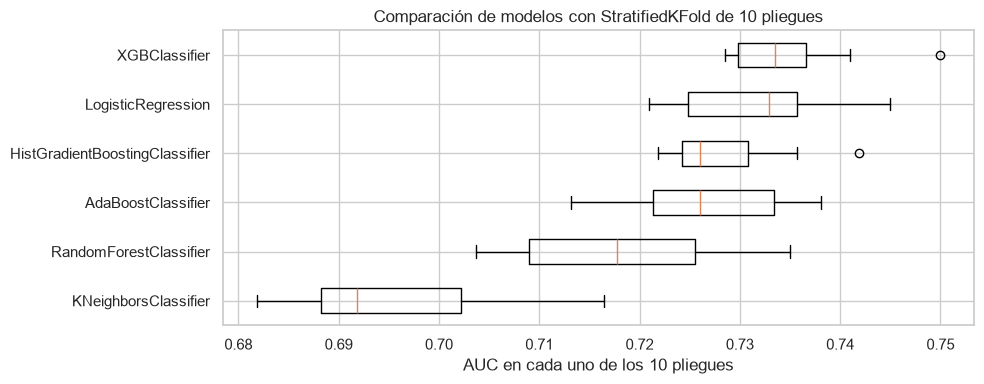

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([resultados_cv[n]["test_auc"] for n in orden[::-1]], vert=False, tick_labels=list(orden[::-1]), widths=0.5)
ax.set_xlabel("AUC en cada uno de los 10 pliegues")
ax.set_title("Comparación de modelos con StratifiedKFold de 10 pliegues")
plt.tight_layout()
guardar_figura("comparacion_modelos", RUN_COMPARACION)

Análisis: la caja de XGBClassifier está a la derecha de todas y sus 10 AUC van de cerca de 0.729 a 0.741, con un pliegue atípico cerca de 0.750. Su mediana es la más alta, aunque muy cerca de la de LogisticRegression, cuya caja se cruza con la de XGBClassifier y es más ancha. Por eso la diferencia entre los dos se revisa con la prueba de Wilcoxon. KNeighborsClassifier queda claramente por debajo del resto.

Prueba de Wilcoxon. Se comprueba si la diferencia de AUC entre el mejor modelo y cada uno de los otros es real o puede deberse a cómo cayeron los pliegues. La prueba compara pliegue por pliegue (es pareada, porque los 10 pliegues son los mismos para todos los modelos) y no supone que los AUC sigan una distribución normal. Un p-valor menor que 0.05 indica que la diferencia es significativa.

In [26]:
# Prueba de Wilcoxon pareada: AUC del mejor modelo frente al de cada uno de los otros en los mismos 10 pliegues.
mejor_nombre, segundo = orden[0], orden[1]
auc_mejor = resultados_cv[mejor_nombre]["test_auc"]
filas = []
for nombre in orden[1:]:
    auc_otro = resultados_cv[nombre]["test_auc"]
    filas.append({"modelo comparado": nombre, "diferencia media de AUC": np.mean(auc_mejor - auc_otro),
                  "pliegues en que gana el mejor": f"{int((auc_mejor > auc_otro).sum())} de {len(auc_mejor)}",
                  "p-valor": stats.wilcoxon(auc_mejor, auc_otro).pvalue})
tabla_wilcoxon = pd.DataFrame(filas).set_index("modelo comparado")
tabla_wilcoxon["diferencia significativa (p < 0.05)"] = np.where(tabla_wilcoxon["p-valor"] < 0.05, "Sí", "No")
p_segundo = tabla_wilcoxon.loc[segundo, "p-valor"]
motivo = (f"tiene el mayor AUC medio en la validación cruzada y su ventaja sobre {segundo} es significativa (p = {p_segundo:.3f})"
          if p_segundo < 0.05 else
          f"tiene el mayor AUC medio en la validación cruzada, aunque su ventaja sobre {segundo} no es significativa (p = {p_segundo:.3f})")
registrar_tabla(RUN_COMPARACION, tabla_wilcoxon, "wilcoxon")
cliente_mlflow.set_tag(RUN_COMPARACION, "modelo_elegido", mejor_nombre)
print(f"Modelo elegido: {mejor_nombre}, porque {motivo}.")
tabla_wilcoxon.round(4)

Modelo elegido: XGBClassifier, porque tiene el mayor AUC medio en la validación cruzada y su ventaja sobre LogisticRegression es significativa (p = 0.037).


,diferencia media de AUC,pliegues en que gana el mejor,p-valor,diferencia significativa (p < 0.05)
modelo comparado,,,,
LogisticRegression,0.0035,8 de 10,0.0371,Sí
HistGradientBoostingClassifier,0.0066,10 de 10,0.0020,Sí
AdaBoostClassifier,0.0084,10 de 10,0.0020,Sí
RandomForestClassifier,0.0166,10 de 10,0.0020,Sí
KNeighborsClassifier,0.0397,10 de 10,0.0020,Sí


Análisis: XGBClassifier le gana a LogisticRegression en 8 de los 10 pliegues, con una diferencia media de 0.0035 de AUC, y la prueba de Wilcoxon indica que esa diferencia es significativa (p = 0.037). Frente a los otros cuatro modelos gana en los 10 pliegues (p = 0.002, el valor más bajo posible con 10 pliegues). Se elige XGBClassifier: tiene el mejor AUC y la ventaja está respaldada por la prueba. Como la diferencia con LogisticRegression es pequeña, la regresión logística queda como una alternativa más simple con un desempeño cercano.

# 9. Ajuste de hiperparámetros con GridSearchCV

El mejor modelo de la sección 8 se ajusta con GridSearchCV, que prueba todas las combinaciones de una grilla de valores con validación cruzada sobre df_train.

Por qué GridSearchCV:

- Se ajusta un solo modelo y cuatro hiperparámetros con pocos valores cada uno, así que probar todas las combinaciones es viable: 120 combinaciones.
- Es exhaustivo y reproducible: con la misma grilla y los mismos pliegues siempre da el mismo resultado, y permite ver cómo cambia el AUC con cada hiperparámetro (mapa de calor más abajo).
- Una búsqueda aleatoria o bayesiana conviene cuando hay muchos hiperparámetros o rangos muy amplios; aquí la grilla cubre el espacio de forma ordenada a un costo bajo.

Validación de la búsqueda: StratifiedKFold de 5 pliegues sobre df_train, con la misma semilla para todas las combinaciones. Cada pliegue de validación tiene unos 4,000 pacientes, y 5 pliegues en lugar de 10 reducen a la mitad el número de ajustes (600 en lugar de 1,200). La métrica es el AUC, la principal del proyecto.

Grilla de búsqueda para XGBClassifier. Se ajustan los cuatro hiperparámetros que más controlan cuánto aprende el modelo y cuánto se sobreajusta:

| Hiperparámetro | Valores | Escala | Por qué |
|---|---|---|---|
| max_depth | 1, 2, 3, 4, 5 | lineal | Profundidad de cada árbol: cuántas variables puede combinar una regla. Con 1, cada árbol mira una sola variable; cada nivel más duplica las hojas posibles, así que basta con valores consecutivos. Árboles más profundos captan más interacciones, pero se sobreajustan con más facilidad |
| learning_rate | 0.03, 0.06, 0.12 | logarítmica (cada valor duplica al anterior) | Cuánto aporta cada árbol. Su efecto es relativo: pasar de 0.03 a 0.06 pesa tanto como pasar de 0.06 a 0.12 |
| n_estimators | 200, 400, 800, 1,600 | logarítmica (cada valor duplica al anterior) | Número de árboles. Va de la mano con learning_rate: con una tasa baja hacen falta más árboles |
| min_child_weight | 1, 10 | logarítmica | Peso mínimo de pacientes en cada hoja. 1 es el valor por defecto de XGBoost y deja que el árbol separe grupos pequeños; 10 obliga a reglas que apliquen a más pacientes, lo que reduce el sobreajuste |

subsample (0.9) y colsample_bytree (0.8) quedan fijos en los valores de la configuración de partida: cada árbol ve el 90% de los pacientes y el 80% de las columnas, una aleatoriedad moderada que ya ayuda a no sobreajustar. Dejarlos fijos mantiene la grilla en 120 combinaciones.

Los valores extienden la configuración de partida (max_depth 4, learning_rate 0.05, 300 árboles) hacia los dos lados, para que el mejor valor no quede en un borde de la grilla. La tabla de resultados indica si alguno quedó en el valor mínimo o máximo probado. Los demás modelos también tienen su grilla definida en el código, por si en otra ejecución ganara otro.

In [27]:
# GridSearchCV sobre el mejor modelo, con StratifiedKFold de 5 pliegues. Cada combinación queda registrada en MLflow.
parametrosGridSearch = {
    "XGBClassifier": {"modelo__max_depth": [1, 2, 3, 4, 5], "modelo__learning_rate": [0.03, 0.06, 0.12],
                      "modelo__n_estimators": [200, 400, 800, 1600], "modelo__min_child_weight": [1, 10]},
    "HistGradientBoostingClassifier": {"modelo__learning_rate": [0.03, 0.06, 0.12], "modelo__max_leaf_nodes": [15, 31, 63],
                                       "modelo__min_samples_leaf": [20, 100], "modelo__max_iter": [200, 400]},
    "LogisticRegression": {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], "modelo__class_weight": [None, "balanced"]},
    "RandomForestClassifier": {"modelo__min_samples_leaf": [2, 5, 15], "modelo__max_features": ["sqrt", 0.3]},
    "AdaBoostClassifier": {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.3, 0.6, 1.0]},
    "KNeighborsClassifier": {"modelo__n_neighbors": [35, 75, 150], "modelo__weights": ["uniform", "distance"]},
}
stratifiedKFold5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
estimador_mejor, pca_mejor = modelos[mejor_nombre]
grilla = parametrosGridSearch[mejor_nombre]
inicio = time.time()
busquedaGridSearch = GridSearchCV(crear_pipeline(clone(estimador_mejor), pca_global=pca_mejor), grilla, scoring="roc_auc",
                                  cv=stratifiedKFold5, n_jobs=max(1, (os.cpu_count() or 1) // HILOS_POR_MODELO),
                                  return_train_score=True).fit(X_train, y_train)
minutos = (time.time() - inicio) / 60
resultados_grid = pd.DataFrame(busquedaGridSearch.cv_results_)
mejores_parametros = {k.replace("modelo__", ""): v for k, v in busquedaGridSearch.best_params_.items()}

# Registro en MLflow: un run por combinación, anidado en el run de la búsqueda.
with iniciar_run(f"gridsearch | {mejor_nombre}") as run:
    RUN_BUSQUEDA = run.info.run_id
    mlflow.log_params({"modelo": mejor_nombre, "metodo": "GridSearchCV", "combinaciones": len(resultados_grid), "pliegues": 5,
                       "metrica": "roc_auc", **{f"mejor_{k}": v for k, v in mejores_parametros.items()}})
    mlflow.log_metrics({"auc_cv_mejor": busquedaGridSearch.best_score_, "minutos": minutos,
                        "auc_entrenamiento_mejor": resultados_grid.loc[busquedaGridSearch.best_index_, "mean_train_score"]})
    for _, fila in resultados_grid.iterrows():
        registrar_variante(" | ".join(f"{k.replace('modelo__', '')}={v}" for k, v in fila["params"].items()),
                           {k.replace("modelo__", ""): v for k, v in fila["params"].items()},
                           {"auc_cv_media": fila["mean_test_score"], "auc_cv_desv": fila["std_test_score"],
                            "auc_entrenamiento": fila["mean_train_score"]})

# Comprobación de bordes: si el mejor valor de un hiperparámetro numérico es el mínimo o el máximo probado.
bordes = [f"{k}={v}" for k, v in mejores_parametros.items()
          if isinstance(v, (int, float)) and len(grilla[f"modelo__{k}"]) > 1 and v in (min(grilla[f"modelo__{k}"]), max(grilla[f"modelo__{k}"]))]
print(f"Combinaciones evaluadas: {len(resultados_grid)} en {minutos:.1f} min | mejor AUC: {busquedaGridSearch.best_score_:.4f} | "
      f"rango: {resultados_grid['mean_test_score'].min():.4f} a {resultados_grid['mean_test_score'].max():.4f}")
print("Mejores hiperparámetros:", mejores_parametros)
print("Mejores valores en un borde de la grilla:", ", ".join(bordes) if bordes else "ninguno")
print(f"AUC en entrenamiento del mejor candidato: {resultados_grid.loc[busquedaGridSearch.best_index_, 'mean_train_score']:.4f}")
columnas_param = [c for c in resultados_grid.columns if c.startswith("param_")]
registrar_tabla(RUN_BUSQUEDA, resultados_grid[columnas_param + ["mean_test_score", "std_test_score", "mean_train_score"]], "resultados_gridsearch")
resultados_grid[columnas_param + ["mean_test_score", "std_test_score", "mean_train_score"]].sort_values(
    "mean_test_score", ascending=False).head(8).rename(columns=lambda c: c.replace("param_modelo__", "")).round(4)

Combinaciones evaluadas: 120 en 3.7 min | mejor AUC: 0.7376 | rango: 0.6970 a 0.7376
Mejores hiperparámetros: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 1600}
Mejores valores en un borde de la grilla: learning_rate=0.03, min_child_weight=1, n_estimators=1600
AUC en entrenamiento del mejor candidato: 0.7840


,learning_rate,max_depth,min_child_weight,n_estimators,mean_test_score,std_test_score,mean_train_score
11,0.03,2,1,1600,0.7376,0.0050,0.7840
15,0.03,2,10,1600,0.7374,0.0049,0.7815
50,0.06,2,1,800,0.7372,0.0053,0.7837
89,0.12,2,1,400,0.7367,0.0051,0.7829
54,0.06,2,10,800,0.7366,0.0044,0.7813
43,0.06,1,1,1600,0.7363,0.0050,0.7530
82,0.12,1,1,800,0.7363,0.0052,0.7531
18,0.03,3,1,800,0.7362,0.0055,0.8014


Análisis: de las 120 combinaciones, la mejor usa árboles de profundidad 2, tasa de aprendizaje 0.03, peso mínimo por hoja de 1 y 1,600 árboles, con un AUC de 0.7376. El rango completo va de 0.6970 a 0.7376, pero las ocho mejores combinaciones quedan entre 0.7362 y 0.7376, así que cerca del óptimo el modelo es poco sensible a los hiperparámetros.

Tres valores quedan en un borde de la grilla, y ninguno indica que haga falta seguir buscando:

- learning_rate = 0.03 y n_estimators = 1,600 se compensan entre sí: las combinaciones con el mismo producto entre tasa y número de árboles dan casi el mismo AUC (0.03 con 1,600 árboles: 0.7376; 0.06 con 800: 0.7372; 0.12 con 400: 0.7367). Bajar más la tasa y subir los árboles solo cambiaría el AUC en milésimas, menos que la variación entre pliegues (desviación de 0.005), y costaría más tiempo de cómputo.
- min_child_weight = 1 es el valor por defecto de XGBoost y el mínimo habitual; con 10 el AUC es prácticamente el mismo (0.7374).

max_depth = 2 sí quedó dentro de la grilla: con profundidad 1 y 3 el mejor AUC es menor (0.7363 y 0.7362). El AUC de entrenamiento del mejor candidato (0.7840) es mayor que el de validación cruzada, una diferencia moderada de sobreajuste que los árboles poco profundos ayudan a contener.

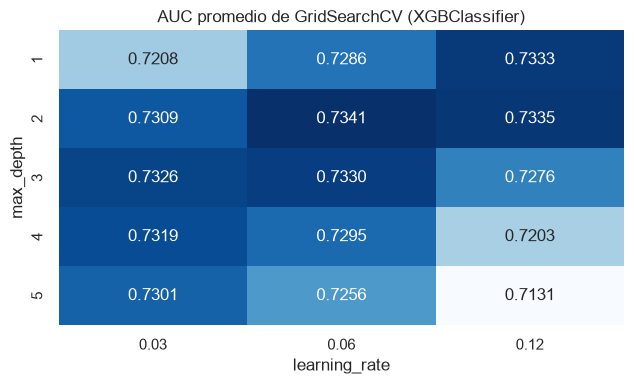

In [28]:
# AUC promedio de GridSearchCV según los dos primeros hiperparámetros de la búsqueda (promediando el resto).
param_fila, param_col = list(grilla)[:2]
mapa_grid = resultados_grid.assign(**{c: resultados_grid[c].astype(str) for c in columnas_param}).pivot_table(
    index=f"param_{param_fila}", columns=f"param_{param_col}", values="mean_test_score", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(mapa_grid, annot=True, fmt=".4f", cmap="Blues", ax=ax, cbar=False)
ax.set_ylabel(param_fila.replace("modelo__", ""))
ax.set_xlabel(param_col.replace("modelo__", ""))
ax.set_title(f"AUC promedio de GridSearchCV ({mejor_nombre})")
plt.tight_layout()
guardar_figura("gridsearch", RUN_BUSQUEDA)

Análisis: el mapa promedia el resto de hiperparámetros (número de árboles y peso mínimo por hoja). Con árboles poco profundos conviene una tasa de aprendizaje más alta, y con árboles profundos una más baja: con profundidad 1 el mejor promedio es con 0.12 (0.7333) y con profundidad 5, con 0.03 (0.7301). La mejor celda es profundidad 2 con 0.06 (0.7341). Los árboles profundos con tasa alta son la peor combinación (0.7131 con profundidad 5 y 0.12), porque se ajustan demasiado rápido a los datos de entrenamiento.

In [29]:
# En df_val: AUC del modelo ajustado frente al modelo sin ajustar, y umbral de alerta.
def formato_parametros(parametros):
    return ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in parametros.items())


pipelineFinal = busquedaGridSearch.best_estimator_
prob_val = pipelineFinal.predict_proba(X_val)[:, 1].astype(float)
pipelineSinAjuste = crear_pipeline(clone(estimador_mejor), pca_global=pca_mejor).fit(X_train, y_train)
auc_val, auc_val_sin = roc_auc_score(y_val, prob_val), roc_auc_score(y_val, pipelineSinAjuste.predict_proba(X_val)[:, 1])

# Umbral de alerta: el que maximiza el índice de Youden (recall menos tasa de falsos positivos) en df_val.
fpr, tpr, umbrales = roc_curve(y_val, prob_val)
UMBRAL = float(umbrales[np.argmax(tpr - fpr)])
pred_val = (prob_val >= UMBRAL).astype(int)
print(f"{mejor_nombre} | hiperparámetros ajustados: {formato_parametros(mejores_parametros)}")
print(f"AUC en df_val: ajustado {auc_val:.4f} | sin ajustar {auc_val_sin:.4f} | diferencia frente a GridSearchCV {busquedaGridSearch.best_score_ - auc_val:+.4f}")
print(f"Umbral de alerta: {UMBRAL:.3f} | recall {recall_score(y_val, pred_val):.3f} | precision {precision_score(y_val, pred_val):.3f}")

with iniciar_run(f"modelo_final | {mejor_nombre}") as run:
    RUN_FINAL = run.info.run_id
    mlflow.log_params({"modelo": mejor_nombre, **mejores_parametros, "umbral": round(UMBRAL, 4),
                       "pacientes_entrenamiento": len(X_train), "motivo_seleccion": motivo})
    mlflow.log_metrics({"auc_cv_gridsearch": busquedaGridSearch.best_score_, "auc_val": auc_val, "auc_val_sin_ajustar": auc_val_sin,
                        "recall_val": recall_score(y_val, pred_val), "precision_val": precision_score(y_val, pred_val)})
    mlflow.sklearn.log_model(pipelineFinal, name="modelo", serialization_format="cloudpickle", input_example=X_train.dropna().head(5))

XGBClassifier | hiperparámetros ajustados: learning_rate=0.03, max_depth=2, min_child_weight=1, n_estimators=1600
AUC en df_val: ajustado 0.7425 | sin ajustar 0.7411 | diferencia frente a GridSearchCV -0.0049
Umbral de alerta: 0.507 | recall 0.734 | precision 0.683


Análisis: en df_val el modelo ajustado alcanza 0.7425 de AUC, frente a 0.7411 sin ajustar: el ajuste mejora poco (0.0014), lo que coincide con la poca sensibilidad que mostró la grilla. Queda 0.0049 por encima del valor de GridSearchCV (0.7376), así que no hay señal de que la búsqueda haya sobreestimado el resultado. El umbral de alerta que mejor equilibra eventos detectados y falsas alarmas es 0.507: con él se detecta el 73.4% de los eventos y el 68.3% de las alertas son correctas. El umbral se fija aquí, antes de ver df_test.

# 10. Evaluación final en df_test

df_test se usa una sola vez, con el modelo y el umbral ya decididos.

In [30]:
# Evaluación final en df_test, que no se usó en ningún paso anterior.
prob_test = pipelineFinal.predict_proba(X_test)[:, 1].astype(float)
pred_test = (prob_test >= UMBRAL).astype(int)
resumen_test = pd.Series({
    "AUC-ROC": roc_auc_score(y_test, prob_test), "average precision": average_precision_score(y_test, prob_test),
    "F1 macro": f1_score(y_test, pred_test, average="macro"), "balanced accuracy": balanced_accuracy_score(y_test, pred_test),
    "recall del evento": recall_score(y_test, pred_test), "precision del evento": precision_score(y_test, pred_test),
    "Brier score": brier_score_loss(y_test, prob_test), "log-loss": log_loss(y_test, prob_test)}, name=mejor_nombre)
CLAVES_METRICAS = {"AUC-ROC": "auc", "average precision": "average_precision", "F1 macro": "f1_macro",
                   "balanced accuracy": "balanced_accuracy", "recall del evento": "recall", "precision del evento": "precision",
                   "Brier score": "brier", "log-loss": "log_loss"}
registrar_metricas(RUN_FINAL, {f"test_{CLAVES_METRICAS[k]}": v for k, v in resumen_test.items()})
print(classification_report(y_test, pred_test, target_names=["Sin evento", "Evento en 12 meses"], digits=3))
resumen_test.round(4).to_frame()

                    precision    recall  f1-score   support

        Sin evento      0.674     0.621     0.646      2029
Evento en 12 meses      0.681     0.730     0.705      2256

          accuracy                          0.678      4285
         macro avg      0.677     0.675     0.675      4285
      weighted avg      0.678     0.678     0.677      4285



,XGBClassifier
AUC-ROC,0.7441
average precision,0.7469
F1 macro,0.6753
balanced accuracy,0.6751
recall del evento,0.7296
precision del evento,0.6813
Brier score,0.2039
log-loss,0.5928


Análisis: en los 4,285 pacientes de df_test el AUC es 0.7441, en línea con la validación cruzada (0.7376 en GridSearchCV) y con df_val (0.7425), lo que confirma que el resultado es estable. Con el umbral de 0.507 el modelo detecta el 73.0% de los eventos (recall) y el 68.1% de sus alertas son correctas (precision). El Brier score de 0.2039 está por debajo de 0.25 y el log-loss de 0.593 por debajo de 0.693, que son los valores que daría predecir siempre 50%.

Intervalo de confianza. Las métricas de df_test salen de una sola muestra de 4,285 pacientes. Con bootstrap (remuestrear df_test con reemplazo 1,000 veces) se estima entre qué valores podrían estar con otra muestra de pacientes parecida.

In [31]:
# Intervalo de confianza del 95% por bootstrap: df_test se remuestrea 1,000 veces con reemplazo
# y en cada muestra se recalculan las métricas con el mismo modelo y el mismo umbral.
rng = np.random.default_rng(SEMILLA)
y_test_arr = y_test.to_numpy()
muestras = []
for _ in range(1000):
    i = rng.integers(0, len(y_test_arr), len(y_test_arr))
    muestras.append({"AUC-ROC": roc_auc_score(y_test_arr[i], prob_test[i]),
                     "recall del evento": recall_score(y_test_arr[i], pred_test[i]),
                     "precision del evento": precision_score(y_test_arr[i], pred_test[i])})
muestras = pd.DataFrame(muestras)
tabla_ic = pd.DataFrame({"valor en df_test": resumen_test[muestras.columns], "IC 95% inferior": muestras.quantile(0.025),
                         "IC 95% superior": muestras.quantile(0.975)}).round(4)
registrar_metricas(RUN_FINAL, {f"test_{CLAVES_METRICAS[k]}_ic_inferior": v for k, v in tabla_ic["IC 95% inferior"].items()}
                   | {f"test_{CLAVES_METRICAS[k]}_ic_superior": v for k, v in tabla_ic["IC 95% superior"].items()})
tabla_ic

,valor en df_test,IC 95% inferior,IC 95% superior
AUC-ROC,0.7441,0.7279,0.7583
recall del evento,0.7296,0.7109,0.7479
precision del evento,0.6813,0.6621,0.7002


Análisis: con otra muestra de pacientes parecida, el AUC estaría con 95% de confianza entre 0.728 y 0.758; el recall, entre 71.1% y 74.8%, y la precision, entre 66.2% y 70.0%. Es decir, el AUC del modelo está alrededor de 0.74 con un margen de unos 0.015 hacia cada lado. Todo el intervalo queda muy por encima de 0.5 (el azar) y de los índices clínicos de la siguiente celda.

Punto de referencia. Para saber cuánto aporta el modelo, se compara su AUC con el de tres índices que el equipo médico ya usa, cada uno por sí solo: el índice de comorbilidad de Sorror, el grupo de riesgo de la enfermedad y la escala de Karnofsky.

In [32]:
# Punto de referencia: AUC en df_test de tres índices clínicos usados por sí solos. A cada paciente se le asigna
# el porcentaje con evento que tenía su valor del índice en df_train (el dato vacío cuenta como un valor más).
def auc_indice(col):
    valor = lambda df: df[col].astype(object).where(df[col].notna(), "Sin dato").astype(str)
    tasa = y_train.groupby(valor(df_train).values).mean()
    return roc_auc_score(y_test, valor(df_test).map(tasa).fillna(y_train.mean()))


referencia = pd.Series({"Índice de comorbilidad de Sorror": auc_indice("indice_comorbilidad_sorror"),
                        "Grupo de riesgo de la enfermedad": auc_indice("grupo_riesgo_enfermedad"),
                        "Escala de Karnofsky": auc_indice("escala_karnofsky"),
                        f"{mejor_nombre} (modelo final)": roc_auc_score(y_test, prob_test)}, name="AUC en df_test")
registrar_tabla(RUN_FINAL, referencia.to_frame(), "referencia_indices_clinicos")
referencia.round(4).to_frame()

,AUC en df_test
Índice de comorbilidad de Sorror,0.5692
Grupo de riesgo de la enfermedad,0.6119
Escala de Karnofsky,0.5654
XGBClassifier (modelo final),0.7441


Análisis: usados por sí solos, los índices que el equipo médico ya conoce ordenan el riesgo mucho peor que el modelo: el índice de Sorror logra un AUC de 0.569, la escala de Karnofsky 0.565 y el grupo de riesgo de la enfermedad 0.612, frente a 0.744 del modelo. Cada índice mira una sola dimensión del paciente; el modelo combina las 57 variables.

## 10.1 Matriz de confusión y curvas

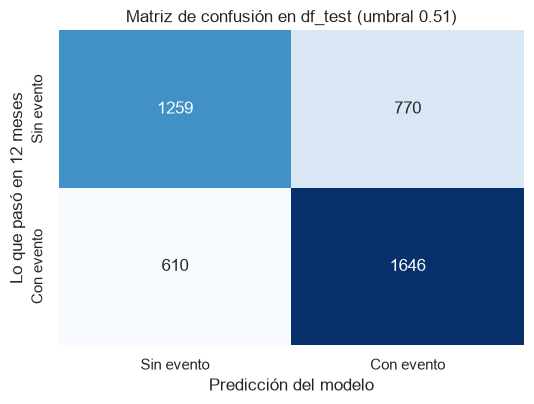

In [33]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Sin evento", "Con evento"], yticklabels=["Sin evento", "Con evento"])
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Lo que pasó en 12 meses")
ax.set_title(f"Matriz de confusión en df_test (umbral {UMBRAL:.2f})")
plt.tight_layout()
guardar_figura("matriz_confusion", RUN_FINAL)

Análisis: de los 2,256 pacientes que sí tuvieron un evento, el modelo alertó a 1,646 y no detectó a 610. De los 2,029 sin evento, 1,259 quedaron bien clasificados y 770 recibieron una alerta de más. En la práctica, un falso negativo es un paciente de alto riesgo con seguimiento habitual y un falso positivo es un control adicional; si el equipo prefiere detectar más eventos, puede bajar el umbral a cambio de más alertas.

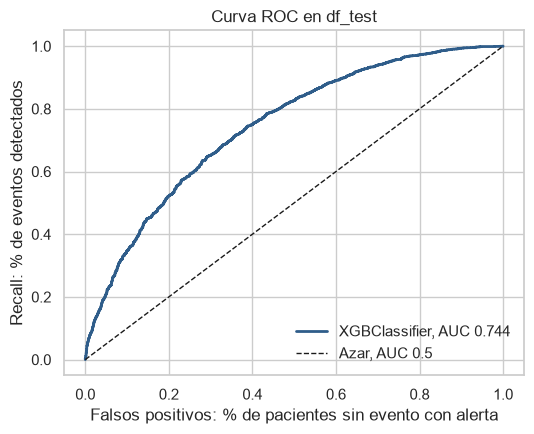

In [34]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
f, t, _ = roc_curve(y_test, prob_test)
ax.plot(f, t, color=AZUL, linewidth=2, label=f"{mejor_nombre}, AUC {roc_auc_score(y_test, prob_test):.3f}")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar, AUC 0.5")
ax.set_xlabel("Falsos positivos: % de pacientes sin evento con alerta")
ax.set_ylabel("Recall: % de eventos detectados")
ax.set_title("Curva ROC en df_test")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
guardar_figura("curva_roc", RUN_FINAL)

Análisis: la curva queda muy por encima de la diagonal del azar en todo su recorrido. Cada punto es un umbral posible: por ejemplo, para detectar cerca del 80% de los eventos hay que aceptar que cerca de la mitad de los pacientes sin evento reciba una alerta. El AUC de 0.744 resume esa capacidad de ordenar a los pacientes por riesgo.

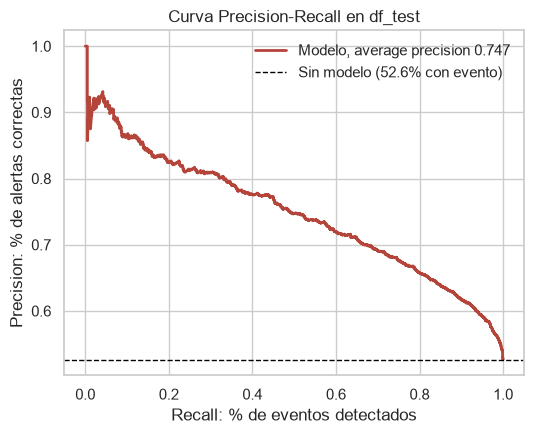

In [35]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
pr, rc, _ = precision_recall_curve(y_test, prob_test)
ax.plot(rc, pr, color=ROJO, linewidth=2, label=f"Modelo, average precision {average_precision_score(y_test, prob_test):.3f}")
ax.axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Sin modelo ({y_test.mean():.1%} con evento)")
ax.set_xlabel("Recall: % de eventos detectados")
ax.set_ylabel("Precision: % de alertas correctas")
ax.set_title("Curva Precision-Recall en df_test")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("curva_pr", RUN_FINAL)

Análisis: sin modelo, alertar a todos daría una precision de 52.6%, la proporción de pacientes con evento. El modelo mantiene una precision de 80% o más mientras detecta hasta cerca del 30% de los eventos, que son los pacientes de mayor riesgo. El average precision de 0.747 está muy por encima de esa línea base.

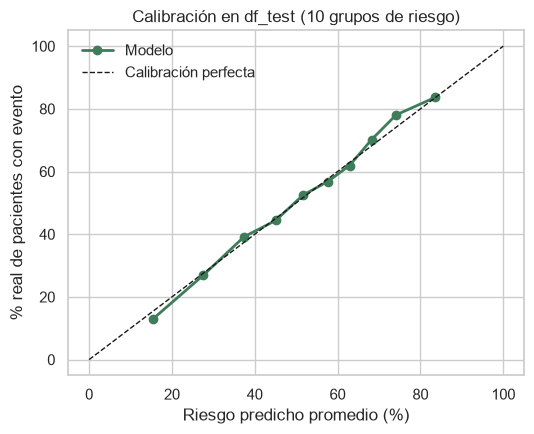

In [36]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
frac_real, prob_media = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
ax.plot(prob_media * 100, frac_real * 100, marker="o", color=VERDE, linewidth=2, label="Modelo")
ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="Calibración perfecta")
ax.set_xlabel("Riesgo predicho promedio (%)")
ax.set_ylabel("% real de pacientes con evento")
ax.set_title("Calibración en df_test (10 grupos de riesgo)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("calibracion", RUN_FINAL)

Análisis: los puntos siguen de cerca la diagonal en casi todo el rango, de 16% a 84% de riesgo predicho. En los extremos hay desvíos pequeños: en el grupo de menor riesgo el modelo predice 16% y ocurre 13%, y en el penúltimo grupo predice 74% y ocurre 78%. Las probabilidades se pueden leer casi de forma literal: entre los pacientes a los que el modelo les asigna cerca de 40% de riesgo, alrededor de 4 de cada 10 tienen un evento.

## 10.2 Riesgo por deciles

Decil de menor riesgo: 13.1% | decil de mayor riesgo: 83.7% | 6.4 veces más


,pacientes,riesgo_medio_predicho,tasa_real_de_evento
decil,,,
D1,429,0.155,0.131
D2,428,0.275,0.269
D3,429,0.374,0.392
D4,428,0.451,0.444
D5,429,0.516,0.524
D6,428,0.576,0.568
D7,428,0.629,0.619
D8,429,0.682,0.702
D9,428,0.741,0.780


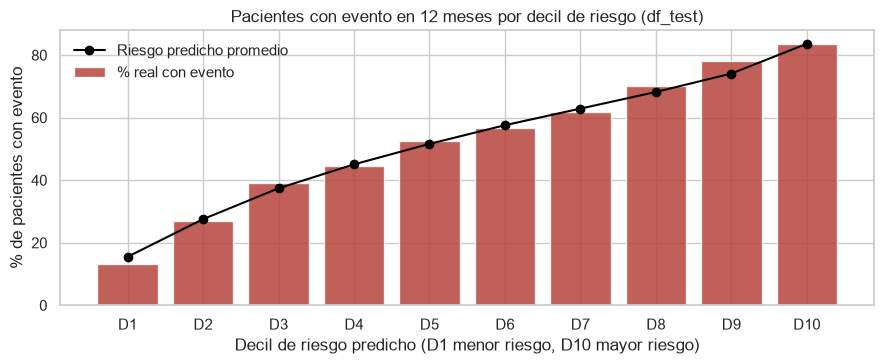

In [37]:
# Porcentaje real de pacientes con evento por decil de riesgo predicho en df_test.
tabla_deciles = pd.DataFrame({"riesgo": prob_test, "evento": y_test.values,
                              "decil": pd.qcut(prob_test, 10, labels=[f"D{i}" for i in range(1, 11)])}).groupby(
    "decil", observed=True).agg(pacientes=("evento", "size"), riesgo_medio_predicho=("riesgo", "mean"), tasa_real_de_evento=("evento", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(tabla_deciles.index.astype(str), tabla_deciles["tasa_real_de_evento"] * 100, color=ROJO, alpha=0.85, label="% real con evento")
ax.plot(tabla_deciles.index.astype(str), tabla_deciles["riesgo_medio_predicho"] * 100, color="black", marker="o", label="Riesgo predicho promedio")
ax.set_xlabel("Decil de riesgo predicho (D1 menor riesgo, D10 mayor riesgo)")
ax.set_ylabel("% de pacientes con evento")
ax.set_title("Pacientes con evento en 12 meses por decil de riesgo (df_test)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("deciles", RUN_FINAL)
bajo, alto = tabla_deciles["tasa_real_de_evento"].iloc[0], tabla_deciles["tasa_real_de_evento"].iloc[-1]
print(f"Decil de menor riesgo: {bajo:.1%} | decil de mayor riesgo: {alto:.1%} | {alto / bajo:.1f} veces más")
registrar_tabla(RUN_FINAL, tabla_deciles, "deciles_df_test")
tabla_deciles.round(3)

Análisis: es la lectura más útil para el equipo clínico. En el 10% de pacientes de menor riesgo solo el 13.1% tuvo un evento en el primer año; en el 10% de mayor riesgo, el 83.7%, es decir, 6.4 veces más. La tasa real sube decil a decil sin excepciones y coincide con el riesgo predicho. Esto permite definir tres niveles: bajo (deciles 1 a 3, de 13% a 39%), intermedio y alto (deciles 8 a 10, de 70% a 84%).

## 10.3 Desempeño por subgrupo

Se revisa el desempeño por grupo de edad, tipo de injerto, periodo del trasplante (los registros de 2018 a 2020 son los más incompletos, sección 5.4) y número de variables vacías, para saber dónde el modelo es más o menos confiable.

In [38]:
# Desempeño por subgrupo clínico en df_test, para saber dónde el modelo es más o menos confiable.
df_resultados = df_test.assign(prob=prob_test, pred=pred_test)
df_resultados["grupo_edad"] = pd.cut(df_resultados["edad_paciente"], [-1, 17.99, 40, 60, 100],
                                     labels=["Menor de 18", "18 a 40", "40 a 60", "Mayor de 60"]).astype(str)
def resumen_por(col):
    filas = [{col: v, "pacientes": len(g), "% con evento": g["evento_12m"].mean() * 100, "AUC": roc_auc_score(g["evento_12m"], g["prob"]),
              "recall del evento": recall_score(g["evento_12m"], g["pred"])}
             for v, g in df_resultados.groupby(col) if len(g) >= 80]
    return pd.DataFrame(filas).set_index(col).round(3)
display(resumen_por("grupo_edad"))
resumen_por("tipo_injerto")

,pacientes,% con evento,AUC,recall del evento
grupo_edad,,,,
18 a 40,1051,53.283,0.708,0.695
40 a 60,1332,59.084,0.707,0.816
Mayor de 60,860,63.953,0.701,0.856
Menor de 18,1042,34.453,0.747,0.401


,pacientes,% con evento,AUC,recall del evento
tipo_injerto,,,,
Bone marrow,1236,35.113,0.737,0.366
Peripheral blood,3049,59.757,0.710,0.816


Análisis: el modelo ordena bien el riesgo en todos los grupos de edad (AUC de 0.701 a 0.747), y mejor aún en los menores de 18. El punto débil es el umbral: en los niños, que tienen un riesgo base mucho menor (34.5% con evento), el umbral general solo detecta el 40.1% de sus eventos. Lo mismo pasa con el injerto de médula ósea (recall de 0.366), un grupo que también tiene un riesgo base bajo (35.1% con evento). Para pacientes pediátricos conviene un umbral propio más bajo.

In [39]:
# Desempeño en df_test según el periodo del trasplante y según cuántas variables vacías tiene el paciente
# (las variables con nulos de la sección 5.4).
df_resultados["periodo_trasplante"] = pd.cut(df_resultados["anio_trasplante"], [2007, 2012, 2017, 2020],
                                             labels=["2008 a 2012", "2013 a 2017", "2018 a 2020"]).astype(str)
df_resultados["variables_vacias"] = pd.cut(df_resultados[COLUMNAS_CON_NULOS].isna().sum(axis=1), [-1, 0, 2, 60],
                                           labels=["0", "1 a 2", "3 o más"]).astype(str)
display(resumen_por("periodo_trasplante"))
resumen_por("variables_vacias")

,pacientes,% con evento,AUC,recall del evento
periodo_trasplante,,,,
2008 a 2012,833,62.305,0.758,0.857
2013 a 2017,2234,53.939,0.736,0.742
2018 a 2020,1218,43.678,0.719,0.577


,pacientes,% con evento,AUC,recall del evento
variables_vacias,,,,
0,2532,60.940,0.70,0.788
1 a 2,1132,39.841,0.76,0.590
3 o más,621,42.190,0.76,0.626


Análisis: por periodo, el AUC baja poco a poco con los años: 0.758 entre 2008 y 2012, 0.736 entre 2013 y 2017 y 0.719 entre 2018 y 2020. En el último periodo hay menos eventos (43.7%) y el recall cae a 57.7%, así que el umbral general detecta menos eventos en los registros recientes. Con los datos vacíos pasa algo parecido: los pacientes sin vacíos tienen más eventos (60.9%) y el modelo detecta el 78.8%; los que tienen uno o más vacíos tienen menos eventos (40% a 42%) y el recall baja a cerca de 60%, aunque el modelo los ordena mejor (AUC de 0.76 frente a 0.70). El modelo no pierde capacidad de ordenar cuando faltan datos; lo que cambia es el riesgo base de esos grupos.

## 10.4 Errores del modelo

Con el umbral elegido, cada paciente de df_test cae en uno de cuatro grupos: evento detectado, evento no detectado (falso negativo), falsa alarma (falso positivo) o sin evento y sin alerta. Se compara el perfil de los cuatro grupos para ver qué tienen en común los casos en que el modelo se equivoca.

In [40]:
# Perfil de aciertos y errores en df_test con el umbral elegido.
df_errores = df_resultados.copy()
df_errores["resultado"] = np.select(
    [(df_errores["pred"] == 1) & (df_errores["evento_12m"] == 1), (df_errores["pred"] == 0) & (df_errores["evento_12m"] == 1),
     (df_errores["pred"] == 1) & (df_errores["evento_12m"] == 0)],
    ["Evento detectado", "Evento no detectado", "Falsa alarma"], "Sin evento y sin alerta")
df_errores["cerca_del_umbral"] = (df_errores["prob"] - UMBRAL).abs() <= 0.10
perfil_errores = df_errores.groupby("resultado").agg(
    pacientes=("id", "size"), riesgo_predicho_medio=("prob", "mean"), pct_a_menos_de_10_puntos_del_umbral=("cerca_del_umbral", "mean"),
    edad_mediana=("edad_paciente", "median"), pct_menores_de_18=("es_pediatrico", "mean"),
    pct_medula_osea=("tipo_injerto", lambda s: (s == "Bone marrow").mean()),
    sorror_mediano=("indice_comorbilidad_sorror", "median"),
    pct_con_datos_vacios=("variables_vacias", lambda s: (s != "0").mean()),
    pct_trasplante_2018_o_despues=("anio_trasplante", lambda s: (s >= 2018).mean()))
columnas_pct = [c for c in perfil_errores.columns if c.startswith("pct_") or c == "riesgo_predicho_medio"]
perfil_errores[columnas_pct] = perfil_errores[columnas_pct] * 100
perfil_errores = perfil_errores.loc[["Evento detectado", "Evento no detectado", "Falsa alarma", "Sin evento y sin alerta"]]
registrar_tabla(RUN_FINAL, perfil_errores, "perfil_errores")
perfil_errores.round(1)

,pacientes,riesgo_predicho_medio,pct_a_menos_de_10_puntos_del_umbral,edad_mediana,pct_menores_de_18,pct_medula_osea,sorror_mediano,pct_con_datos_vacios,pct_trasplante_2018_o_despues
resultado,,,,,,,,,
Evento detectado,1646,69.0,25.3,50.8,8.7,9.7,2.0,26.1,18.7
Evento no detectado,610,37.9,46.9,33.2,35.2,45.1,1.0,46.4,36.9
Falsa alarma,770,63.9,42.9,49.7,9.4,12.9,2.0,32.2,26.9
Sin evento y sin alerta,1259,30.5,26.6,18.8,48.5,55.8,1.0,62.9,38.0


Análisis: los dos tipos de error tienen perfiles distintos. Los eventos no detectados (610) se parecen a los pacientes de bajo riesgo: edad mediana de 33 años, 35% son menores de 18, 45% recibió médula ósea, Sorror mediano de 1 y 46% tiene algún dato vacío, frente a 9%, 10% y 26% en los eventos que sí se detectan. También son más comunes en los trasplantes de 2018 o después (37% frente a 19%). Las falsas alarmas (770) se parecen a los pacientes con evento: edad mediana de 50 años, pocos niños (9%) y Sorror mediano de 2. Además, cerca de la mitad de los errores (47% de los eventos no detectados y 43% de las falsas alarmas) tienen un riesgo predicho a menos de 10 puntos del umbral, es decir, son casos dudosos.

Errores: 1,380 de 4,285 pacientes (32.2%) | a menos de 10 puntos del umbral: 44.6%
Eventos no detectados con riesgo predicho menor a 30%: 139 | falsas alarmas con riesgo mayor a 70%: 182


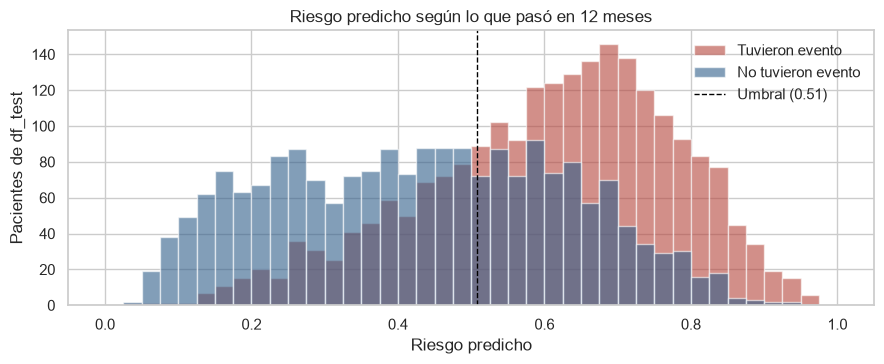

In [41]:
# Distribución del riesgo predicho según lo que pasó: los errores son las barras rojas a la izquierda del umbral
# (eventos no detectados) y las azules a la derecha (falsas alarmas).
fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.linspace(0, 1, 41)
ax.hist(prob_test[y_test_arr == 1], bins=bordes, alpha=0.6, color=ROJO, label="Tuvieron evento")
ax.hist(prob_test[y_test_arr == 0], bins=bordes, alpha=0.6, color=AZUL, label="No tuvieron evento")
ax.axvline(UMBRAL, color="black", linestyle="--", linewidth=1, label=f"Umbral ({UMBRAL:.2f})")
ax.set_xlabel("Riesgo predicho")
ax.set_ylabel("Pacientes de df_test")
ax.set_title("Riesgo predicho según lo que pasó en 12 meses")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("errores", RUN_FINAL)
es_error = df_errores["resultado"].isin(["Evento no detectado", "Falsa alarma"])
print(f"Errores: {es_error.sum():,} de {len(df_errores):,} pacientes ({es_error.mean():.1%}) | "
      f"a menos de 10 puntos del umbral: {df_errores.loc[es_error, 'cerca_del_umbral'].mean():.1%}")
print(f"Eventos no detectados con riesgo predicho menor a 30%: {((df_errores['resultado'] == 'Evento no detectado') & (df_errores['prob'] < 0.30)).sum()} | "
      f"falsas alarmas con riesgo mayor a 70%: {((df_errores['resultado'] == 'Falsa alarma') & (df_errores['prob'] > 0.70)).sum()}")

Análisis: los pacientes con evento (rojo) se concentran a la derecha y los que no lo tuvieron (azul) a la izquierda, pero las dos distribuciones se cruzan en la zona media, entre 40% y 70% de riesgo. Ahí se acumulan muchos de los errores: de los 1,380 (32.2% de df_test), el 44.6% tiene un riesgo a menos de 10 puntos del umbral. Los errores con mucha seguridad son menos: 139 eventos no detectados tenían un riesgo menor a 30% y 182 falsas alarmas un riesgo mayor a 70%. Esos casos, con un perfil que el modelo no logra distinguir, son los que más conviene revisar con el equipo clínico.

# 11. Análisis a 6, 12 y 18 meses

Para revisar si el horizonte de 12 meses fue una buena elección, se repite el entrenamiento con el evento a 6 y a 18 meses.

In [42]:
# El mismo pipeline (con los hiperparámetros elegidos) entrenado para predecir el evento a 6, 12 y 18 meses.
# Se usan solo los pacientes que no están en df_test, con StratifiedKFold de 5 pliegues.
df_sin_test = df_clean[~df_clean["id"].isin(df_test["id"])]
filas = []
for h in (6, 12, 18):
    df_h = construir_objetivo(df_sin_test, h)
    auc = cross_validate(clone(pipelineFinal), df_h[COLUMNAS_ENTRADA], df_h["evento_12m"], cv=stratifiedKFold5, scoring="roc_auc", n_jobs=-1)["test_score"]
    filas.append({"horizonte (meses)": h, "pacientes": len(df_h),
                  "% excluidos por censura": ((df_clean["evento"] == 0) & (df_clean["meses_hasta_evento"] < h)).mean() * 100,
                  "% con evento en el horizonte": df_h["evento_12m"].mean() * 100, "AUC (media)": auc.mean(), "AUC (desv.)": auc.std()})
tabla_horizontes = pd.DataFrame(filas).set_index("horizonte (meses)")
registrar_metricas(RUN_FINAL, {f"auc_horizonte_{h}_meses": tabla_horizontes.loc[h, "AUC (media)"] for h in tabla_horizontes.index})
tabla_horizontes.round(3)

,pacientes,% excluidos por censura,% con evento en el horizonte,AUC (media),AUC (desv.)
horizonte (meses),,,,,
6,24496,0.066,29.066,0.734,0.006
12,24277,0.826,52.626,0.739,0.004
18,23589,3.764,55.602,0.741,0.009


Análisis: el modelo rinde casi igual en los tres horizontes (AUC de 0.734, 0.739 y 0.741), así que la elección se basa en el problema y no en la métrica. A 6 meses solo el 29.1% de los pacientes tiene evento, porque se pierde casi la mitad de los que ocurren en el primer año. A 18 meses la proporción casi no sube (55.6% frente a 52.6%), pero se excluye el 3.8% de los pacientes por censura, cuatro veces y media más que a 12 meses. El horizonte de 12 meses captura casi todos los eventos con la menor pérdida de pacientes.

# 12. Explicabilidad

Tres preguntas: cómo se leen las contribuciones del modelo, de qué variables depende más y por qué le asigna a un paciente concreto su riesgo. Se responden con la escala de log-odds (12.1), la importancia por permutación (12.2) y SHAP (12.3 y 12.4).

## 12.1 Cómo leer las contribuciones: log-odds y probabilidad

Los modelos de este tipo no suman probabilidades sino log-odds, una escala en la que los efectos de las variables sí se pueden sumar. Se pasa de una a otra con la fórmula probabilidad = 1 / (1 + e^(−log-odds)): un log-odds de 0 equivale a 50% de riesgo, los valores positivos suben el riesgo y los negativos lo bajan.

Lo importante para leer las gráficas de SHAP es que una misma contribución no siempre mueve el riesgo lo mismo: lo mueve más cuando el paciente está cerca del 50% que cuando ya está muy alto o muy bajo. La tabla muestra el riesgo que resulta de sumar varias contribuciones a distintos riesgos de partida.

In [43]:
# Riesgo final (%) al sumar una contribución en log-odds a distintos riesgos de partida.
a_probabilidad = lambda z: 1 / (1 + np.exp(-z))
a_log_odds = lambda p: np.log(p / (1 - p))
riesgos_partida = [0.10, 0.30, 0.50, 0.70, 0.90]
tabla_escala = pd.DataFrame({f"{c:+.1f} log-odds": [a_probabilidad(a_log_odds(p) + c) * 100 for p in riesgos_partida]
                             for c in [-1.0, -0.5, -0.2, 0.2, 0.5, 1.0]},
                            index=[f"riesgo de partida {p:.0%}" for p in riesgos_partida]).round(1)
tabla_escala

,-1.0 log-odds,-0.5 log-odds,-0.2 log-odds,+0.2 log-odds,+0.5 log-odds,+1.0 log-odds
riesgo de partida 10%,3.9,6.3,8.3,11.9,15.5,23.2
riesgo de partida 30%,13.6,20.6,26.0,34.4,41.4,53.8
riesgo de partida 50%,26.9,37.8,45.0,55.0,62.2,73.1
riesgo de partida 70%,46.2,58.6,65.6,74.0,79.4,86.4
riesgo de partida 90%,76.8,84.5,88.1,91.7,93.7,96.1


Análisis: la tabla muestra por qué SHAP se lee en log-odds. Una contribución de +0.5 lleva a un paciente de 50% a 62.2% (12 puntos más), pero a uno de 90% solo lo lleva a 93.7% (4 puntos) y a uno de 10% a 15.5% (5 puntos). Los log-odds se suman igual sin importar dónde esté el paciente; los puntos de probabilidad no. Por eso las gráficas de SHAP están en log-odds y, para leerlas en lenguaje clínico, el notebook también traduce las contribuciones a puntos de riesgo.

## 12.2 Importancia por permutación: cuánto empeora el modelo sin cada variable

Se desordena una variable en df_val (se mezclan sus valores entre pacientes, así pierde su relación con el resultado) y se mide cuánto empeoran dos métricas:

- El log-loss, que castiga las probabilidades equivocadas, y más aún las equivocadas con mucha seguridad (decir 90% de riesgo a alguien que no tuvo el evento). Más bajo es mejor. Si al desordenar una variable el log-loss sube mucho, el modelo depende de ella.
- El AUC, que mide si el modelo sigue ordenando bien a los pacientes por riesgo.

Se repite 5 veces por variable y las 17 variables HLA se desordenan juntas, como un solo factor. A diferencia de SHAP, esta medida no depende de cómo funciona el modelo por dentro: solo compara sus resultados con y sin la variable.

Modelo con los datos originales en df_val: log-loss 0.5972 | AUC 0.7425


,aumento del log-loss,desv. del aumento,caída del AUC
variable,,,
intensidad_acondicionamiento,0.0129,0.0020,0.0177
sexo_donante_receptor,0.0114,0.0010,0.0154
anio_trasplante,0.0093,0.0007,0.0114
compatibilidad_hla,0.0088,0.0007,0.0109
serologia_cmv,0.0080,0.0003,0.0107
enfermedad_principal,0.0066,0.0010,0.0089
escala_karnofsky,0.0064,0.0010,0.0083
indice_comorbilidad_sorror,0.0062,0.0012,0.0068
profilaxis_injerto_huesped,0.0052,0.0014,0.0062


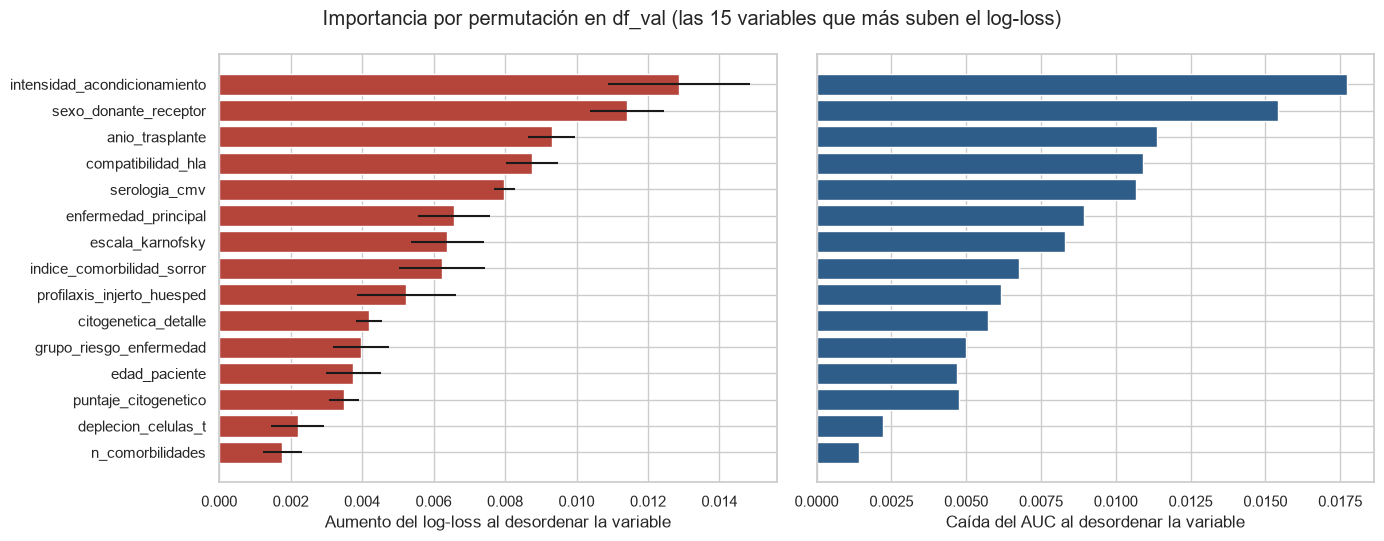

In [44]:
# Importancia por permutación en df_val: cuánto sube el log-loss y cuánto baja el AUC al desordenar cada variable.
rng = np.random.default_rng(SEMILLA)
prob_val_base = pipelineFinal.predict_proba(X_val)[:, 1]
logloss_base, auc_base = log_loss(y_val, prob_val_base), roc_auc_score(y_val, prob_val_base)
grupos_permutacion = {"compatibilidad_hla": COLUMNAS_HLA} | {c: [c] for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA}
filas = []
for variable, columnas in grupos_permutacion.items():
    cambios_logloss, cambios_auc = [], []
    for _ in range(5):
        orden_filas = rng.permutation(len(X_val))
        X_permutado = X_val.copy()
        for c in columnas:
            X_permutado[c] = X_val[c].to_numpy()[orden_filas]
        prob = pipelineFinal.predict_proba(X_permutado)[:, 1]
        cambios_logloss.append(log_loss(y_val, prob) - logloss_base)
        cambios_auc.append(auc_base - roc_auc_score(y_val, prob))
    filas.append({"variable": variable, "aumento del log-loss": np.mean(cambios_logloss),
                  "desv. del aumento": np.std(cambios_logloss), "caída del AUC": np.mean(cambios_auc)})
importancia_permutacion = pd.DataFrame(filas).set_index("variable").sort_values("aumento del log-loss", ascending=False)
registrar_tabla(RUN_FINAL, importancia_permutacion, "importancia_permutacion")

top = importancia_permutacion.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
axes[0].barh(top.index, top["aumento del log-loss"], xerr=top["desv. del aumento"], color=ROJO)
axes[0].set_xlabel("Aumento del log-loss al desordenar la variable")
axes[1].barh(top.index, top["caída del AUC"], color=AZUL)
axes[1].set_xlabel("Caída del AUC al desordenar la variable")
plt.suptitle("Importancia por permutación en df_val (las 15 variables que más suben el log-loss)")
plt.tight_layout()
guardar_figura("importancia_permutacion", RUN_FINAL)
print(f"Modelo con los datos originales en df_val: log-loss {logloss_base:.4f} | AUC {auc_base:.4f}")
importancia_permutacion.head(15).round(4)

Análisis: con los datos originales el modelo tiene en df_val un log-loss de 0.597 y un AUC de 0.743. La variable que más empeora el modelo al desordenarla es la intensidad del acondicionamiento (el log-loss sube 0.013 y el AUC baja 0.018), seguida de la combinación de sexos de donante y receptor, el año del trasplante, la compatibilidad HLA y la serología de CMV. Las dos medidas dan casi el mismo orden. Los efectos son pequeños porque cada variable aporta solo una parte del riesgo. Algunas variables comparten información (por ejemplo, la edad del paciente con es_pediatrico y con la diferencia de edad con el donante), así que al desordenar una el modelo puede apoyarse en las otras y su importancia aparece más baja.

## 12.3 SHAP: efecto de cada variable

SHAP reparte la predicción de cada paciente entre sus variables: cuánto sube o baja el riesgo cada una frente al riesgo promedio. Las contribuciones de un paciente, sumadas al valor base, dan exactamente su predicción. Se calcula sobre 2,000 pacientes de df_val con el modelo final, y los valores de las columnas que ve el modelo (One-Hot y componentes HLA) se suman por variable original.

In [45]:
# SHAP sobre el modelo final. Los valores se calculan en las columnas que ve el modelo (One-Hot y componentes HLA)
# y luego se suman por variable original, para explicar en el lenguaje del registro clínico.
columnTransformer = pipelineFinal.named_steps["columnTransformer"]
estimador_final = pipelineFinal.named_steps["modelo"]
nombres_columnas = columnTransformer.get_feature_names_out()
if isinstance(estimador_final, LogisticRegression):
    fondo = columnTransformer.transform(X_train.sample(500, random_state=SEMILLA))
    explicadorShap = shap.LinearExplainer(estimador_final, shap.maskers.Independent(fondo, max_samples=len(fondo)))
    ESCALA_SHAP, n_shap = "log-odds", 2000
elif isinstance(estimador_final, (XGBClassifier, HistGradientBoostingClassifier)):
    explicadorShap = shap.TreeExplainer(estimador_final)
    ESCALA_SHAP, n_shap = "log-odds", 2000
elif isinstance(estimador_final, RandomForestClassifier):
    explicadorShap = shap.TreeExplainer(estimador_final)
    ESCALA_SHAP, n_shap = "probabilidad", 2000
else:
    fondo = shap.sample(columnTransformer.transform(X_train), 100, random_state=SEMILLA)
    explicadorShap = shap.Explainer(lambda x: estimador_final.predict_proba(x)[:, 1], fondo, seed=SEMILLA)
    ESCALA_SHAP, n_shap = "probabilidad", 300
X_shap = X_val.sample(n_shap, random_state=SEMILLA)
valores_shap = explicadorShap(columnTransformer.transform(X_shap))
if valores_shap.values.ndim == 3:
    valores_shap = valores_shap[:, :, 1]


def variable_original(nombre):
    bloque, resto = nombre.split("__", 1)
    if bloque == "hla":
        return "compatibilidad_hla"
    if bloque == "num":
        return resto
    return next(c for c in sorted(COLUMNAS_CATEGORICAS, key=len, reverse=True) if resto.startswith(c + "_"))


df_shap = pd.DataFrame(valores_shap.values, columns=[variable_original(n) for n in nombres_columnas]).T.groupby(level=0).sum().T
valor_base = float(np.atleast_1d(valores_shap.base_values)[0])
a_riesgo = a_probabilidad if ESCALA_SHAP == "log-odds" else (lambda z: z)
riesgo_base = a_riesgo(valor_base)
print(f"Pacientes explicados: {len(X_shap)} | columnas del modelo: {len(nombres_columnas)} | variables originales: {df_shap.shape[1]}")
print(f"Escala de SHAP: {ESCALA_SHAP} | valor base: {valor_base:.3f}, que equivale a un riesgo de {riesgo_base:.1%}")

Pacientes explicados: 2000 | columnas del modelo: 181 | variables originales: 41
Escala de SHAP: log-odds | valor base: 0.104, que equivale a un riesgo de 52.6%


Análisis: SHAP calcula una contribución para cada una de las 181 columnas del modelo y esas contribuciones se suman en las 41 variables originales; los componentes HLA quedan juntos como compatibilidad_hla. El punto de partida (valor base) es 0.104 en log-odds, que equivale al 52.6% de riesgo promedio. Cada paciente parte de ahí y sus variables lo suben o lo bajan.

,SHAP medio absoluto (log-odds),puntos de riesgo en promedio
sexo_donante_receptor,0.189,3.910
intensidad_acondicionamiento,0.182,3.819
compatibilidad_hla,0.152,3.190
profilaxis_injerto_huesped,0.149,3.093
anio_trasplante,0.141,2.945
puntaje_citogenetico,0.121,2.499
indice_comorbilidad_sorror,0.120,2.399
deplecion_celulas_t,0.114,2.334
grupo_riesgo_enfermedad,0.112,2.299
serologia_cmv,0.108,2.218


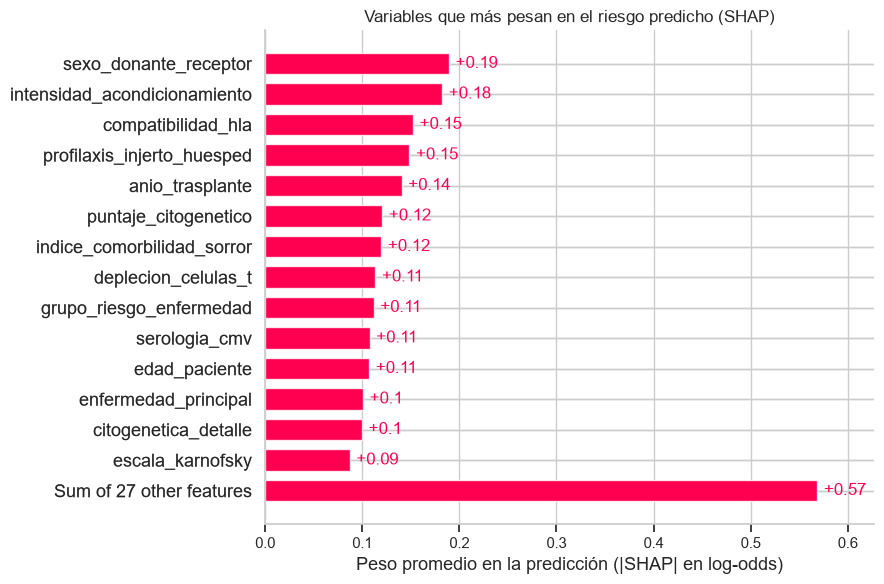

In [46]:
# Importancia global: promedio del valor absoluto de SHAP de cada variable original.
importancia_shap = df_shap.abs().mean().sort_values(ascending=False)
datos_color = X_shap.assign(compatibilidad_hla=pd.to_numeric(X_shap["hla_alta_res_8"], errors="coerce"))
explicacion = shap.Explanation(values=df_shap[importancia_shap.index].values, base_values=np.full(len(df_shap), valor_base),
                               data=datos_color[importancia_shap.index].apply(pd.to_numeric, errors="coerce").values,
                               feature_names=list(importancia_shap.index))
shap.plots.bar(explicacion, max_display=15, show=False)
plt.gcf().set_size_inches(9, 6)
plt.xlabel(f"Peso promedio en la predicción (|SHAP| en {ESCALA_SHAP})")
plt.title("Variables que más pesan en el riesgo predicho (SHAP)")
plt.tight_layout()
guardar_figura("shap_importancia", RUN_FINAL)

# La misma importancia en puntos de riesgo: cuánto cambiaría en promedio la probabilidad de cada paciente
# si se quitara solo la contribución de esa variable.
total_shap = valor_base + df_shap.sum(axis=1)
puntos_riesgo = pd.DataFrame({c: (a_riesgo(total_shap) - a_riesgo(total_shap - df_shap[c])).abs() * 100 for c in df_shap.columns}).mean()
tabla_importancia_shap = pd.DataFrame({f"SHAP medio absoluto ({ESCALA_SHAP})": importancia_shap,
                                       "puntos de riesgo en promedio": puntos_riesgo[importancia_shap.index]})
registrar_tabla(RUN_FINAL, tabla_importancia_shap, "importancia_shap")
tabla_importancia_shap.head(15).round(3)

Análisis: las variables que más pesan son la combinación de sexos de donante y receptor (3.9 puntos de riesgo en promedio), la intensidad del acondicionamiento (3.8), la compatibilidad HLA (3.2), profilaxis_injerto_huesped, los medicamentos para evitar que las células del donante ataquen al paciente (3.1), y el año del trasplante (2.9). Les siguen puntaje_citogenetico (el resultado de un examen genético de la enfermedad), el índice de Sorror, deplecion_celulas_t, el grupo de riesgo de la enfermedad, serologia_cmv y la edad, todas entre 2.1 y 2.5 puntos. El orden coincide en buena parte con la importancia por permutación: intensidad del acondicionamiento, sexo de donante y receptor, compatibilidad HLA y año del trasplante están entre las cinco primeras en las dos medidas.

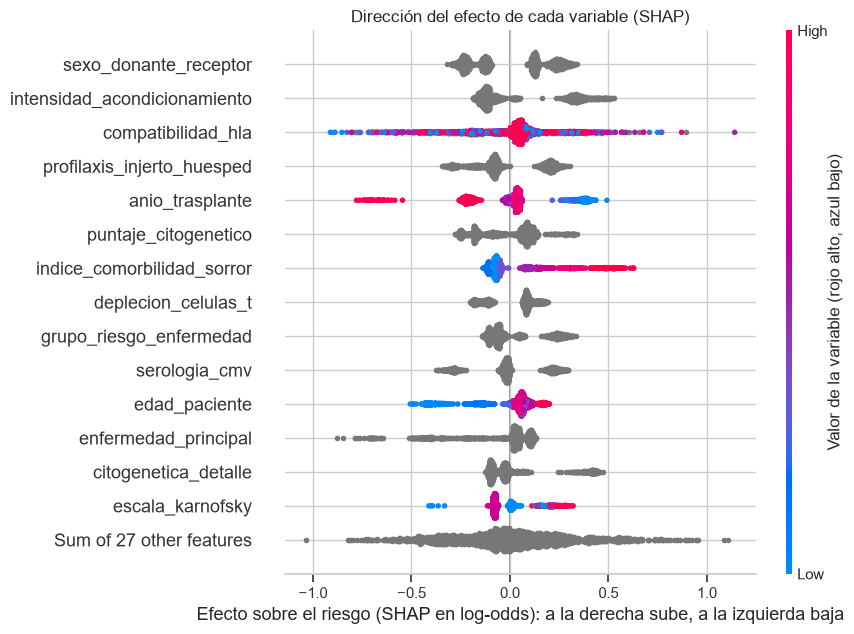

In [47]:
# Beeswarm: cada punto es un paciente. A la derecha la variable sube el riesgo, a la izquierda lo baja.
# El color indica el valor de las variables numéricas (rojo alto, azul bajo); las categóricas salen en gris.
shap.plots.beeswarm(explicacion, max_display=15, show=False)
figura = plt.gcf()
figura.set_size_inches(9, 6.5)
figura.axes[0].set_xlabel(f"Efecto sobre el riesgo (SHAP en {ESCALA_SHAP}): a la derecha sube, a la izquierda baja")
if len(figura.axes) > 1:
    figura.axes[-1].set_ylabel("Valor de la variable (rojo alto, azul bajo)")
plt.title("Dirección del efecto de cada variable (SHAP)")
plt.tight_layout()
guardar_figura("shap_beeswarm", RUN_FINAL)

Análisis: en las variables numéricas, el color indica la dirección del efecto. Un índice de Sorror alto (rojo) sube el riesgo y uno bajo (azul) lo baja. En la edad, los pacientes más jóvenes (azul) tienen las contribuciones más negativas. En el año del trasplante, los más recientes (rojo) quedan a la izquierda, con menos riesgo, hasta cerca de -0.75. La sección 5.5 mostró que esos años también son los de registros más incompletos, así que este efecto puede reflejar mejores tratamientos o datos que todavía no estaban completos, y no debe leerse como una causa. Las variables categóricas aparecen en gris y se detallan en la siguiente gráfica.

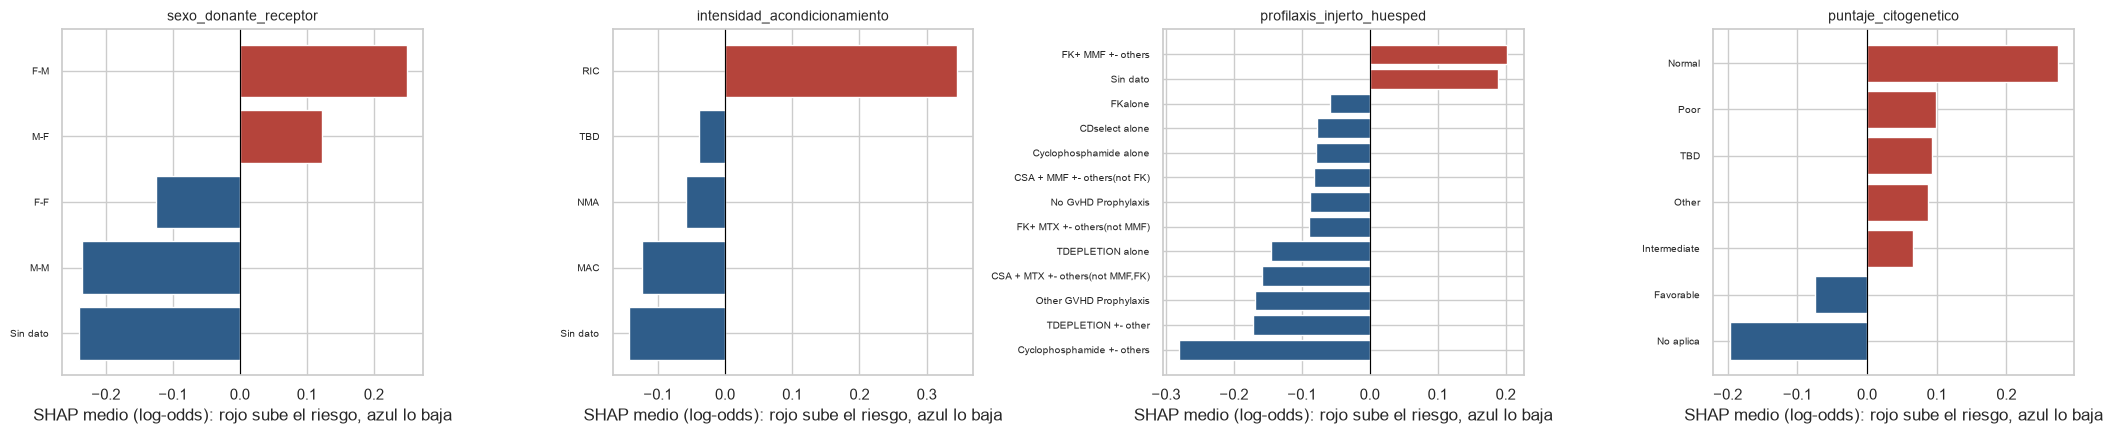

In [48]:
# SHAP medio por categoría en las cuatro variables categóricas más importantes.
top_categoricas = [c for c in importancia_shap.index if c in COLUMNAS_CATEGORICAS][:4]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, col in zip(axes, top_categoricas):
    media = df_shap[col].groupby(X_shap[col].fillna("Sin dato").values).agg(["mean", "size"])
    media = media[media["size"] >= 15].sort_values("mean")
    ax.barh(media.index.astype(str), media["mean"], color=[ROJO if v > 0 else AZUL for v in media["mean"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(f"SHAP medio ({ESCALA_SHAP}): rojo sube el riesgo, azul lo baja")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
guardar_figura("shap_categorias", RUN_FINAL)

Análisis: en sexo_donante_receptor, donante mujer con receptor hombre (F-M) es la combinación que más sube el riesgo, seguida de donante hombre con receptor mujer (M-F); donante y receptor hombres (M-M) y los pocos pacientes sin dato lo bajan de forma parecida. El acondicionamiento de intensidad reducida (RIC) sube el riesgo y el intenso (MAC) lo baja; los pacientes sin dato reciben el valor más frecuente (MAC) y por eso se comportan de forma parecida. En profilaxis_injerto_huesped, el esquema FK + MMF y los pacientes sin dato (que reciben ese mismo valor, el más frecuente) suben el riesgo, y casi todos los demás esquemas lo bajan, sobre todo Cyclophosphamide +- others. En puntaje_citogenetico, los resultados normal, de mal pronóstico (Poor), pendiente (TBD), otro e intermedio suben el riesgo; el favorable lo baja y No aplica lo baja aún más. Que un resultado normal suba el riesgo más que uno de mal pronóstico no tiene una explicación clínica evidente: es un patrón de estos datos que conviene revisar con el equipo médico.

In [49]:
# Efecto de los valores más influyentes sobre un paciente promedio. Para cada una de las 8 variables con más peso se toma
# el valor que más sube el riesgo y el que más lo baja (grupos con 50 o más pacientes) y su SHAP medio se traduce a puntos
# de riesgo sobre el riesgo promedio. Las variables numéricas con muchos valores se agrupan en quintiles.
def grupos_shap(col):
    serie = X_shap["hla_alta_res_8"] if col == "compatibilidad_hla" else X_shap[col]
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() > 12:
        return pd.qcut(serie, 5, duplicates="drop").astype(object).map(
            lambda iv: f"{iv.left:.0f} a {iv.right:.0f}" if isinstance(iv, pd.Interval) else "Sin dato")
    return serie.astype(object).where(serie.notna(), "Sin dato").astype(str)


filas = []
for col in importancia_shap.index[:8]:
    media = df_shap[col].groupby(grupos_shap(col).values).agg(["mean", "size"])
    media = media[media["size"] >= 50]
    for direccion, valor in (("sube", media["mean"].idxmax()), ("baja", media["mean"].idxmin())):
        filas.append({"variable": col, "efecto": direccion, "valor": valor, "pacientes": int(media.loc[valor, "size"]),
                      f"SHAP medio ({ESCALA_SHAP})": media.loc[valor, "mean"],
                      "puntos de riesgo sobre un paciente promedio": (a_riesgo(valor_base + media.loc[valor, "mean"]) - riesgo_base) * 100})
efectos_tipicos = pd.DataFrame(filas).set_index(["variable", "efecto"])
registrar_tabla(RUN_FINAL, efectos_tipicos, "efectos_tipicos")
print(f"Paciente promedio: riesgo de {riesgo_base:.1%}")
efectos_tipicos.round(3)

Paciente promedio: riesgo de 52.6%


valor  pacientes  \
variable                     efecto                                          
sexo_donante_receptor        sube                           F-M        541   
                             baja                           M-M        549   
intensidad_acondicionamiento sube                           RIC        575   
                             baja                      Sin dato        331   
compatibilidad_hla           sube                             8        988   
                             baja                             5        106   
profilaxis_injerto_huesped   sube             FK+ MMF +- others        740   
                             baja    Cyclophosphamide +- others        159   
anio_trasplante              sube                   2008 a 2012        411   
                             baja                   2017 a 2018        501   
puntaje_citogenetico         sube                        Normal         58   
                             baja                     No aplica        537   
indice_comorbilidad_sorror   sube                           6.0         50   
                             baja                           1.0        357   
deplecion_celulas_t          sube                            No       1254   
                             baja                           Yes        732   

                                     SHAP medio (log-odds)  \
variable                     efecto                          
sexo_donante_receptor        sube                    0.249   
                             baja                   -0.235   
intensidad_acondicionamiento sube                    0.345   
                             baja                   -0.143   
compatibilidad_hla           sube                    0.033   
                             baja                   -0.090   
profilaxis_injerto_huesped   sube                    0.202   
                             baja                   -0.280   
anio_trasplante              sube                    0.272   
                             baja                   -0.210   
puntaje_citogenetico         sube                    0.274   
                             baja                   -0.197   
indice_comorbilidad_sorror   sube                    0.492   
                             baja                   -0.106   
deplecion_celulas_t          sube                    0.098   
                             baja                   -0.141   

                                     puntos de riesgo sobre un paciente promedio  
variable                     efecto                                               
sexo_donante_receptor        sube                                          6.133  
                             baja                                         -5.864  
intensidad_acondicionamiento sube                                          8.442  
                             baja                                         -3.570  
compatibilidad_hla           sube                                          0.816  
                             baja                                         -2.243  
profilaxis_injerto_huesped   sube                                          5.003  
                             baja                                         -6.992  
anio_trasplante              sube                                          6.694  
                             baja                                         -5.255  
puntaje_citogenetico         sube                                          6.730  
                             baja                                         -4.923  
indice_comorbilidad_sorror   sube                                         11.871  
                             baja                                         -2.655  
deplecion_celulas_t          sube                                          2.434  
                             baja                                         -3.515

Análisis: la tabla traduce SHAP a puntos de riesgo sobre un paciente promedio (52.6%). El valor que más sube el riesgo es un índice de Sorror de 6 (11.9 puntos más, aunque solo 50 pacientes de la muestra lo tienen), seguido de la intensidad reducida del acondicionamiento (RIC, 8.4 puntos), un examen citogenético normal (6.7), los trasplantes de 2008 a 2012 (6.7) y la combinación F-M (6.1). Los que más lo bajan son la profilaxis Cyclophosphamide +- others (7.0 puntos menos), la combinación M-M (5.9), los trasplantes de 2017 a 2018 (5.3) y el examen citogenético No aplica (4.9). Esta tabla explica por qué la importancia global y el efecto de un valor concreto no siempre coinciden: el sexo de donante y receptor mueve unos 6 puntos a casi todos los pacientes, mientras que un Sorror de 6 mueve casi 12, pero a pocos.

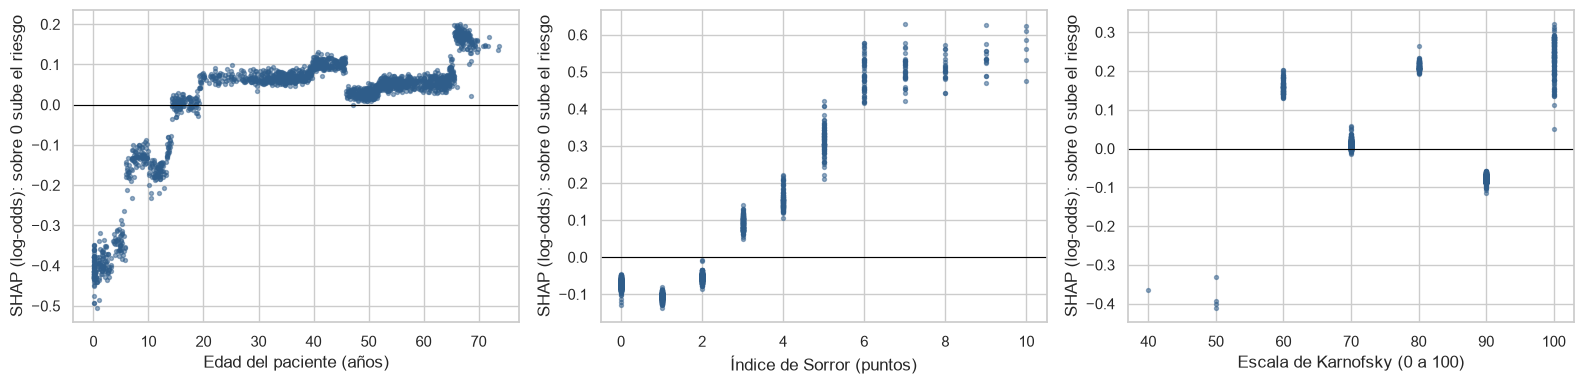

In [50]:
# Dependencia: cómo cambia la contribución de tres variables numéricas según su valor.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, titulo) in zip(axes, {"edad_paciente": "Edad del paciente (años)", "indice_comorbilidad_sorror": "Índice de Sorror (puntos)",
                                     "escala_karnofsky": "Escala de Karnofsky (0 a 100)"}.items()):
    ax.scatter(X_shap[col], df_shap[col], s=8, alpha=0.5, color=AZUL)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(titulo)
    ax.set_ylabel(f"SHAP ({ESCALA_SHAP}): sobre 0 sube el riesgo")
plt.tight_layout()
guardar_figura("shap_dependencia", RUN_FINAL)

Análisis: en la edad, los niños pequeños tienen la contribución más negativa (alrededor de -0.4 y hasta -0.5), el efecto cruza el cero cerca de los 15 años, se mantiene estable y positivo en los adultos y vuelve a subir cerca de los 65. En el índice de Sorror el patrón es casi una escalera: de 0 a 2 puntos baja el riesgo, desde 3 lo sube y desde 6 se estabiliza en el valor más alto (cerca de +0.5). La escala de Karnofsky no muestra un patrón ordenado: 60, 80 y 100 suben el riesgo, 70 queda cerca de cero, 90 lo baja y los pocos pacientes con 40 o 50 también lo bajan. Que una escala de 100 (el mejor estado funcional) suba el riesgo no tiene sentido clínico, así que el efecto de Karnofsky depende de otras variables y no debe leerse por sí solo.

## 12.4 Explicación de pacientes individuales

El gráfico de cascada parte del valor base (el riesgo promedio) y suma, una por una, las contribuciones de las variables de ese paciente hasta llegar a su predicción. Las barras rojas suben el riesgo y las azules lo bajan. Debajo de cada gráfico, una tabla traduce las contribuciones más grandes a puntos de riesgo: cuánto cambiaría la probabilidad del paciente si se quitara solo esa contribución.

,valor del paciente,contribución (log-odds),puntos de riesgo
indice_comorbilidad_sorror,7.0,0.500,2.410
citogenetica_detalle,Poor,0.389,1.777
intensidad_acondicionamiento,RIC,0.320,1.413
enfermedad_cardiaca,Yes,0.313,1.380
enfermedad_pulmonar_severa,Yes,0.301,1.318
escala_karnofsky,80.0,0.232,0.986
profilaxis_injerto_huesped,FK+ MMF +- others,0.220,0.929
serologia_cmv,-/+,0.208,0.874


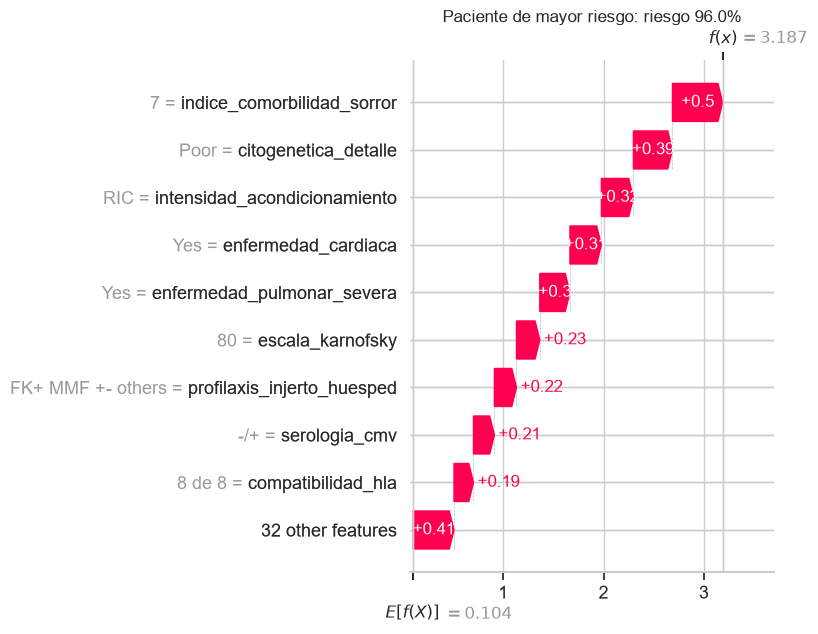

In [51]:
# Explicación individual del paciente con mayor riesgo de la muestra.
prob_shap = pipelineFinal.predict_proba(X_shap)[:, 1]


def explicar_paciente(posicion, titulo, nombre_figura):
    fila = df_shap.iloc[posicion]
    hla8 = X_shap.iloc[posicion]["hla_alta_res_8"]
    valores = [(hla8 if hla8 == "No aplica" else f"{hla8} de 8") if c == "compatibilidad_hla" else X_shap.iloc[posicion].get(c, "")
               for c in fila.index]
    valores = ["Sin dato" if not isinstance(v, str) and pd.isna(v) else v for v in valores]
    plt.figure(figsize=(9, 5))
    shap.plots.waterfall(shap.Explanation(values=fila.values, base_values=valor_base, data=np.array(valores, dtype=object),
                                          feature_names=list(fila.index)), max_display=10, show=False)
    plt.title(f"{titulo}: riesgo {prob_shap[posicion]:.1%}")
    plt.tight_layout()
    guardar_figura(nombre_figura, RUN_FINAL)
    # Puntos de riesgo de cada variable: cuánto cambiaría la probabilidad si se quitara solo su contribución.
    total = valor_base + fila.sum()
    principales = fila.reindex(fila.abs().sort_values(ascending=False).index[:8])
    return pd.DataFrame({"valor del paciente": [valores[list(fila.index).index(c)] for c in principales.index],
                         f"contribución ({ESCALA_SHAP})": principales.values,
                         "puntos de riesgo": [(a_riesgo(total) - a_riesgo(total - v)) * 100 for v in principales.values]},
                        index=principales.index).round(3)


explicar_paciente(int(np.argmax(prob_shap)), "Paciente de mayor riesgo", "shap_paciente_alto")

Análisis: este paciente tiene un riesgo de 96.0%. Parte del 52.6% promedio y lo que más lo empuja hacia arriba es un índice de Sorror de 7, citogenetica_detalle en Poor (un resultado genético de mal pronóstico), acondicionamiento de intensidad reducida, enfermedad cardíaca, enfermedad pulmonar severa, una escala de Karnofsky de 80, la profilaxis FK + MMF y serologia_cmv en -/+ (el donante no ha tenido contacto con el citomegalovirus y el paciente sí). Ninguna de las variables que se muestran le baja el riesgo. La tabla muestra que, como ya está cerca del 100%, quitar cualquiera de esas contribuciones le bajaría el riesgo solo entre 0.9 y 2.4 puntos: en riesgos extremos cada factor mueve poco la probabilidad, como mostró la sección 12.1.

In [52]:
# Explicación individual del paciente con menor riesgo de la muestra.
explicar_paciente(int(np.argmin(prob_shap)), "Paciente de menor riesgo", "shap_paciente_bajo")

,valor del paciente,contribución (log-odds),puntos de riesgo
enfermedad_principal,HIS,-0.678,-4.104
serologia_cmv,+/-,-0.271,-1.358
sexo_donante_receptor,M-M,-0.230,-1.129
compatibilidad_hla,7 de 8,-0.222,-1.086
puntaje_citogenetico,No aplica,-0.182,-0.873
anio_trasplante,2018,-0.180,-0.866
deplecion_celulas_t,Yes,-0.170,-0.812
edad_paciente,11.611,-0.166,-0.793


Análisis: este paciente tiene un riesgo de 4.6%. Es un niño de 11 años con una enfermedad histiocítica (HIS), la de menos eventos en la sección 5.2, trasplantado en 2018, con donante y receptor hombres, compatibilidad HLA de 7 de 8, serología de CMV +/- y sin dato de intensidad del acondicionamiento. La contribución más grande viene de la enfermedad principal (-0.68 en log-odds, 4.1 puntos de riesgo); la siguen la serología de CMV, la combinación M-M, la compatibilidad HLA y el examen citogenético No aplica. Son muchos factores pequeños que suman en la misma dirección: además de los nueve que se muestran, las otras 32 variables restan 0.87 en log-odds.

# 13. Exportación del modelo y registro en MLflow

El pipeline elegido se reentrena con todo df_model (df_train, df_val y df_test) con los mismos hiperparámetros, para aprovechar todos los pacientes en la aplicación. Las métricas reportadas siguen siendo las del modelo entrenado solo con df_train, porque el modelo reentrenado ya no tiene pacientes nuevos con qué medirse.

Archivos que se guardan en despliegue/artefactos/ y que usa la aplicación:

- modelo_hct.joblib: el Pipeline completo (preprocesamiento y modelo).
- metadatos.json: umbral, métricas, intervalos, comparación de modelos, resultado del ajuste, deciles, importancias, reglas de limpieza, opciones válidas y rangos del formulario.
- fondo_shapley.csv: 200 pacientes de referencia para las explicaciones de la aplicación.
- pacientes_ejemplo.csv: 5 pacientes para probar la aplicación.
- requirements_modelo.txt: versiones de las librerías con que se entrenó.

En MLflow el modelo de despliegue queda registrado con el nombre riesgo_post_trasplante, junto con una copia de estos archivos.

In [53]:
# Exportación para el despliegue.
pipelineDespliegue = clone(pipelineFinal).fit(df_model[COLUMNAS_ENTRADA], df_model["evento_12m"])
joblib.dump(pipelineDespliegue, CARPETA_ARTEFACTOS / "modelo_hct.joblib")

# Datos de referencia para las explicaciones y pacientes de ejemplo (sin las columnas de resultado).
df_raw.drop(columns=["efs", "efs_time"]).sample(200, random_state=SEMILLA).to_csv(CARPETA_ARTEFACTOS / "fondo_shapley.csv", index=False)
df_raw.drop(columns=["efs", "efs_time"]).sample(5, random_state=7).to_csv(CARPETA_ARTEFACTOS / "pacientes_ejemplo.csv", index=False)

# Variables que se piden en el formulario de la aplicación: las de df_raw que llegan al modelo, antes de la limpieza.
df_formulario = df_raw.rename(columns=NOMBRES).drop(columns=COLUMNAS_ELIMINADAS + COLUMNAS_PROTEGIDAS + ["id", "evento", "meses_hasta_evento"])
a_python = lambda v: float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer, int)) else v

metadatos = {
    "modelo": mejor_nombre,
    "hiperparametros": {k: a_python(v) for k, v in mejores_parametros.items()},
    "seleccion": f"{mejor_nombre}, porque {motivo}",
    "umbral": UMBRAL,
    "nombres_originales": NOMBRES,
    "columnas_eliminadas": COLUMNAS_ELIMINADAS,
    "variables_geneticas": VARIABLES_GENETICAS,
    "columnas_entrada": COLUMNAS_ENTRADA,
    "descripciones": {NOMBRES[k]: v for k, v in descripcion_oficial.items() if k in NOMBRES and isinstance(v, str)},
    "fuente_diccionario": "https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data",
    "variables_formulario": list(df_formulario.columns),
    "opciones": {c: sorted(df_formulario[c].dropna().astype(str).unique().tolist()) for c in df_formulario.select_dtypes(exclude="number").columns},
    "rangos": {c: [a_python(df_formulario[c].min()), a_python(df_formulario[c].median()), a_python(df_formulario[c].max())]
               for c in df_formulario.select_dtypes("number").columns},
    "metricas_prueba": {k: float(v) for k, v in resumen_test.items()},
    "intervalos_prueba": {k: [float(tabla_ic.loc[k, "IC 95% inferior"]), float(tabla_ic.loc[k, "IC 95% superior"])] for k in tabla_ic.index},
    "comparacion_modelos": {n: {"auc_cv_media": float(resultados_cv[n]["test_auc"].mean()), "auc_cv_desv": float(resultados_cv[n]["test_auc"].std())}
                            for n in orden},
    "ajuste": {"metodo": "GridSearchCV", "combinaciones": int(len(resultados_grid)), "auc_cv_gridsearch": float(busquedaGridSearch.best_score_),
               "auc_val_ajustado": float(auc_val), "auc_val_sin_ajustar": float(auc_val_sin)},
    "deciles_prueba": tabla_deciles.reset_index().astype({"decil": str}).round(4).to_dict(orient="records"),
    "importancia_shap": importancia_shap.round(5).astype(float).to_dict(),
    "escala_shap": ESCALA_SHAP,
    "importancia_shap_puntos": puntos_riesgo[importancia_shap.index].round(4).astype(float).to_dict(),
    "importancia_permutacion": importancia_permutacion["aumento del log-loss"].round(5).astype(float).to_dict(),
    "tasa_base": float(df_model["evento_12m"].mean()),
    "pacientes_despliegue": int(len(df_model)),
    "semilla": SEMILLA,
    "versiones": VERSIONES,
}
(CARPETA_ARTEFACTOS / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
(CARPETA_ARTEFACTOS / "requirements_modelo.txt").write_text(
    "\n".join(f"{k}=={VERSIONES[k]}" for k in ["scikit-learn", "pandas", "numpy", "joblib", "xgboost"]) + "\n", encoding="utf-8")

# Registro del modelo de despliegue en MLflow, con una copia de los artefactos.
with iniciar_run(f"modelo_despliegue | {mejor_nombre}") as run:
    mlflow.log_params({"modelo": mejor_nombre, **mejores_parametros, "umbral": round(UMBRAL, 4), "pacientes_entrenamiento": len(df_model)})
    mlflow.log_metrics({f"test_{CLAVES_METRICAS[k]}": v for k, v in resumen_test.items()})
    mlflow.sklearn.log_model(pipelineDespliegue, name="modelo", serialization_format="cloudpickle",
                             input_example=X_train.dropna().head(5), registered_model_name="riesgo_post_trasplante")
    mlflow.log_artifacts(str(CARPETA_ARTEFACTOS), "artefactos_despliegue")
print("Archivos exportados:", sorted(p.name for p in CARPETA_ARTEFACTOS.iterdir()))

Archivos exportados: ['fondo_shapley.csv', 'metadatos.json', 'modelo_hct.joblib', 'pacientes_ejemplo.csv', 'requirements_modelo.txt']


Successfully registered model 'riesgo_post_trasplante'.
Created version '1' of model 'riesgo_post_trasplante'.


Análisis: la exportación deja en despliegue/artefactos/ los cinco archivos que usa la aplicación. El modelo de despliegue se reentrenó con los 28,562 pacientes de df_model y quedó registrado en MLflow como la versión 1 del modelo riesgo_post_trasplante, junto con una copia de estos archivos.

# 14. Conclusiones, condiciones de validez y próximos pasos

## Resultados

- El problema de supervivencia se convirtió en una clasificación a 12 meses porque la decisión clínica es binaria, el 96.8% de los eventos ocurre en el primer año y la censura solo obliga a excluir al 0.8% de los pacientes. Los horizontes de 6 y 18 meses dan casi el mismo AUC, pero pierden eventos o pacientes.
- La limpieza eliminó 2 variables con más de 50% de nulos y marcó como No aplica los vacíos de las 21 variables genéticas. El resto se imputa dentro del Pipeline con el valor más frecuente, lo que redujo de 31.4 a 6.7 puntos la caída del riesgo al borrarle datos a un paciente, aunque no la elimina del todo.
- PCA redujo el bloque HLA de 88 a 28 columnas sin perder capacidad. Las clases están casi balanceadas y SMOTE no mejoró el resultado.
- XGBClassifier fue el mejor de seis modelos (AUC de 0.7349 ± 0.0062 en validación cruzada) y su ventaja sobre LogisticRegression, el segundo, es significativa según la prueba de Wilcoxon (p = 0.037). Ajustado con GridSearchCV (120 combinaciones) usa árboles de profundidad 2, tasa de aprendizaje 0.03 y 1,600 árboles.
- En df_test, que no se usó para ninguna decisión, logra un AUC de 0.744 (con 95% de confianza, entre 0.728 y 0.758), detecta el 73.0% de los eventos y el 68.1% de sus alertas son correctas, con probabilidades bien calibradas. Los índices clínicos usados por separado (Sorror, Karnofsky y grupo de riesgo de la enfermedad) no pasan de 0.612.
- El modelo separa con claridad a los pacientes: 13.1% de eventos en el decil de menor riesgo y 83.7% en el de mayor riesgo.
- Se equivoca sobre todo en casos dudosos cerca del umbral y en eventos de pacientes con perfil de bajo riesgo: niños, injertos de médula ósea y formularios incompletos. En los niños el umbral general solo detecta el 40.1% de los eventos.
- Según SHAP y la importancia por permutación, el riesgo depende sobre todo de la intensidad del acondicionamiento, la combinación de sexos de donante y receptor, la compatibilidad HLA, la profilaxis, el año del trasplante y la fragilidad del paciente (Sorror y edad).

## Condiciones de validez

- A qué datos aplica: pacientes de trasplante alogénico como los del registro del CIBMTR entre 2008 y 2020, con la información disponible antes del trasplante. Los datos de la competencia son sintéticos: reproducen los patrones del registro real, pero no son pacientes reales.
- Qué garantiza: en pacientes de esa misma población, un AUC de alrededor de 0.74 (entre 0.728 y 0.758 con 95% de confianza) y probabilidades que se pueden leer de forma casi literal.
- Qué no garantiza: el desempeño en otros países, centros o años futuros, porque la validación no separó por fechas y los años recientes tienen registros incompletos; que el patrón de los datos vacíos se repita en otros registros; ni una lectura causal de los factores. Algunos efectos no tienen sentido clínico (un resultado citogenético normal sube el riesgo más que uno de mal pronóstico y una escala de Karnofsky de 100 lo sube), así que el modelo sirve para ordenar pacientes por riesgo, no para explicar por qué ocurre el evento.

## Próximos pasos para llevarlo a producción

- Validarlo con pacientes reales de un centro, idealmente de años recientes, y medir de nuevo el AUC y la calibración.
- Recalibrarlo con datos locales y fijar un umbral propio para niños y para injertos de médula ósea.
- Revisar con el equipo médico los efectos que no tienen sentido clínico antes de usar las explicaciones con pacientes.
- Integrarlo con la historia clínica, vigilar en el tiempo los datos vacíos y el desempeño, y volver a entrenarlo cuando cambie la población.